# Разработка интеллектуальной системы оценки для «AutoValue AI»
- Автор: Макарова Елизавета Алексеевна
- Дата: 29.09.2026
---

## Введение
### Цель проекта и постановка задачи машинного обучения
**Цель:** разработать и внедрить модель машинного обучения для прогнозирования рыночной стоимость автомобиля с целью интеграции в мобильное приложение AutoValue AI. 

Ранее оценка стоимости полагалась на штат из 50 экспертов-оценщиков, что приводило к ряду проблем:
- **Человеческий фактор**: эксперты не способны в уме учитывать сложные нелинейные зависимости между множеством характеристик авто и его ценой.
- **Низкая скорость обработки**: ручной анализ каждого объявления и сбор источников требуют от эксперта слишком много времени.
- **Риск ошибок**: высокая вероятность случайных ошибок и опечаток из-за невнимательности при больших объемах сделок.

**Для бизнеса важно:**
- Минимизировать прямые финансовые потери от сильного занижения стоимости автомобиля, сохраняя маржинальность сделок;
- Снизить долю случаев необоснованного завышения цены, чтобы избежать потери доверия пользователей и оттока аудитории из приложения;
- Обеспечить прозрачность и интерпретируемость прогнозов, чтобы команда продукта понимала ключевые драйверы цены, а конечные пользователи доверяли оценке сервиса.

### Постановка задач машинного обучения
1. Изучить представленные данные, содержащие информацию о 80000+ сделок компании.
2. Провести ИАД
3. Обучить модели регрессии: `XGBoost`, `CatBoost` и `LightGBM`. Провести тюнинг модели.
4. Сравнить модели по метрикам:
   - *Базовые*: `RMSE`, `MAE`, `R²`
   - *Бизнес метрики*: `Overpricing Rate` (доля случаев, когда модель завысила цену более чем на 20%), `Underpricing Loss` — суммарная потеря, когда цена была занижена более чем на 20%.
5. Проанализировать, какие марки авто и регионы чаще страдают от систематического завышения или занижения цены.

### Описание данных
| Признак | Описание | Значимость для бизнеса |
|---|---|---|
| `brand` | Марка автомобиля | Фундамент цены: престиж и надёжность бренда |
| `make_year` | Год выпуска | Главный счётчик амортизации: чем старше автомобиль, тем дешевле |
| `mileage_kmpl` | Пробег (км) | Реальный физический износ автомобиля |
| `engine_cc` | Объём двигателя (в кубических сантиметрах) | Влияет на мощность, налоги и интерес покупателей |
| `fuel_type` | Тип топлива | Экономичность против мощности. Важный фактор ликвидности |
| `transmission` | Тип коробки передач | «Автомат» или «механика» — ключевой фактор комфорта |
| `owner_count` | Количество владельцев по ПТС | Юридическая чистота и аккуратность эксплуатации |
| `color` | Цвет автомобиля | Психологический фактор: популярные цвета продаются быстрее |
| `service_history` | Наличие сервисной книжки | Подтверждает, что за машиной ухаживали вовремя |
| `accidents_reported` | Количество зафиксированных ДТП | Сильно бьёт по цене и безопасности будущей сделки |
| `insurance_valid` | Действительна ли страховка | Снижает первичные расходы покупателя после сделки |
| `region` | Макрорегион РФ, в котором продаётся автомобиль: Москва, Сибирь, Юг | Позволяет модели учитывать региональную специфику цен |
| `price_rub` | Целевой признак: рыночная стоимость автомобиля в рублях | Реальная сумма сделки, которую нужно предсказать |

## Подготовка среды и библиотек
Для начала установим и настроем необходимые версии библиотек:

In [1]:
%pip install -q pandas numpy matplotlib scikit-learn imblearn seaborn phik joblib missingno optuna mlxtend shap xgboost catboost lightgbm 

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik
import warnings
import joblib
import missingno as msno
import scipy
import os
import optuna
import shap 

from itertools import product
from scipy.stats import mstats
from IPython.display import FileLink
from pandas.api.types import is_float_dtype
import time   

from phik.phik import phik_matrix

from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,  
    mean_squared_error, 
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
    log_loss,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    auc,
    ConfusionMatrixDisplay, 
    brier_score_loss
)

from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.preprocessing import (
    RobustScaler, 
    StandardScaler, 
    OneHotEncoder, 
    TargetEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import TransformerMixin, BaseEstimator
from sklearn.compose import make_column_selector
from sklearn.calibration import (
    CalibratedClassifierCV, 
    calibration_curve, 
    CalibrationDisplay
)
from sklearn.feature_selection import (
    VarianceThreshold, 
    mutual_info_classif, 
    mutual_info_regression, 
    RFE, RFECV, SelectKBest, 
    SequentialFeatureSelector as SFS, 
    SelectFromModel, 
    f_classif, f_regression
)
from sklearn.frozen import FrozenEstimator
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, StackingRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.tree import plot_tree
from sklearn.inspection import permutation_importance

from mlxtend.evaluate.time_series import (
    GroupTimeSeriesSplit,
    plot_splits,
    print_cv_info,
    print_split_info,
)
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 15)
np.random.seed(42)

Зафиксируем версии пакетов в `requirements.txt`:

In [3]:
!pip freeze > requirements.txt

### Загрузка датасетов

In [4]:
df_train = pd.read_csv('datasets/ds_s16_train_data.csv', sep=',')
df_test = pd.read_csv('datasets/ds_s16_test_data.csv', sep=',')

In [5]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           8000 non-null   int64  
 1   mileage_kmpl        8000 non-null   float64
 2   engine_cc           8000 non-null   int64  
 3   fuel_type           8000 non-null   str    
 4   owner_count         8000 non-null   int64  
 5   brand               8000 non-null   str    
 6   transmission        8000 non-null   str    
 7   color               8000 non-null   str    
 8   service_history     8000 non-null   str    
 9   accidents_reported  8000 non-null   int64  
 10  insurance_valid     8000 non-null   str    
 11  price_rub           8000 non-null   int64  
 12  region              8000 non-null   str    
dtypes: float64(1), int64(5), str(7)
memory usage: 812.6 KB


In [6]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           2000 non-null   int64  
 1   mileage_kmpl        2000 non-null   float64
 2   engine_cc           2000 non-null   int64  
 3   fuel_type           2000 non-null   str    
 4   owner_count         2000 non-null   int64  
 5   brand               2000 non-null   str    
 6   transmission        2000 non-null   str    
 7   color               2000 non-null   str    
 8   service_history     2000 non-null   str    
 9   accidents_reported  2000 non-null   int64  
 10  insurance_valid     2000 non-null   str    
 11  price_rub           2000 non-null   int64  
 12  region              2000 non-null   str    
dtypes: float64(1), int64(5), str(7)
memory usage: 203.3 KB


In [7]:
df_train.head(5)

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
0,2002,9.699999999999999,1800,Diesel,2,Hyundai,Manual,Silver,Partial,0,No,242073,Урал
1,2004,16.100000000000001,1500,Diesel,3,Hyundai,Manual,Black,Unknown,0,No,426029,Москва
2,2005,10.510000000000000,5000,Diesel,2,Ford,Manual,Gray,Full,0,No,727050,Юг
3,2019,14.270000000000000,2000,Petrol,5,Hyundai,Manual,White,Full,1,Yes,753168,Дальний Восток
4,2015,21.719999999999999,1000,Petrol,1,Toyota,Automatic,Black,Full,0,Yes,733390,Сибирь


### Выводы
Датасет содержит информацию об автомобилях и совершенных с ними сделках. Тренировочная выборка `df_train` включает 8 000 записей, тестовая выборка `df_test` — 2 000 записей. Обе таблицы имеют идентичную структуру: 13 колонок, описывающих характеристики автомобиля, историю его обслуживания и итоговую цену сделки.

1. **Типы данных:**
   - В датасете присутствуют три типа данных: `float64` (1 колонка), `int64` (5 колонок) и `str` (7 колонок).
   - **Числовые признаки** (`make_year`, `mileage_kmpl`, `engine_cc`, `owner_count`, `accidents_reported`, `price_rub`) уже имеют корректный числовой тип требуют только корректировку разрядности.
   - **Категориальные признаки** (`fuel_type`, `brand`, `transmission`, `color`, `service_history`, `insurance_valid`, `region`) имеют строковый тип. Признаки стоит привести к категориальному типу, а также для корректной работы алгоритмов машинного обучения (в частности, CatBoost, LightGBM, XGBoost) их необходимо закодировать. Оптимальным решением будет использование One-Hot Encoding для признаков с небольшим числом уникальных значений и Target Encoding / частотного кодирования — для признаков с высокой кардинальностью.
   - Признак `make_year` является дискретным числовым.

2. **Пропуски в данных:**
   - Пропуски в тренировочной и тестовой выборках **полностью отсутствуют**.
   - Стоит проверить категориальные признаки на наличие скрытых пропусков.

3. **Названия столбцов:**
   - Все названия столбцов уже приведены к стандарту **snake_case** и написаны на английском языке. Дополнительное переименование не требуется.

4. **Целевая переменная:**
   - Целевой переменной является `price_rub` — стоимость автомобиля в рублях.
   - На этапе EDA необходимо изучить её распределение: проверить наличие выбросов, сильной асимметрии и при необходимости применить логарифмическое преобразование (`log1p`) для стабилизации дисперсии и улучшения качества моделей.

## Первичная предобработка данных
### Работа с типами данных

In [8]:
""" 
    Посмотрим количество уникальных значений в столбцах, чтобы понять, 
    какие стоит приводить к категориальному типу данных:
"""
for col in df_train.columns:
    print(f'{str(df_train[col].dtype):<8} - {col}: {df_train[col].nunique()}')

int64    - make_year: 29
float64  - mileage_kmpl: 2108
int64    - engine_cc: 10
str      - fuel_type: 3
int64    - owner_count: 5
str      - brand: 10
str      - transmission: 2
str      - color: 6
str      - service_history: 3
int64    - accidents_reported: 6
str      - insurance_valid: 2
int64    - price_rub: 7929
str      - region: 6


In [9]:
df_train.head()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
0,2002,9.699999999999999,1800,Diesel,2,Hyundai,Manual,Silver,Partial,0,No,242073,Урал
1,2004,16.100000000000001,1500,Diesel,3,Hyundai,Manual,Black,Unknown,0,No,426029,Москва
2,2005,10.510000000000000,5000,Diesel,2,Ford,Manual,Gray,Full,0,No,727050,Юг
3,2019,14.270000000000000,2000,Petrol,5,Hyundai,Manual,White,Full,1,Yes,753168,Дальний Восток
4,2015,21.719999999999999,1000,Petrol,1,Toyota,Automatic,Black,Full,0,Yes,733390,Сибирь


**Из этого можно сделать вывод**
- *Числовые призаки*
    - int: `price_rub` - будем преобразовывать к int32; 
    - float: `mileage_kmpl` - преобразуем в float32;
- *Числовые дискретные*: `make_year` (int), `engine_cc` (int), `owner_count` (int), `accidents_reported` (int) - понизим разрядность до int32;
- *Бинарные*: `insurance_valid` (str) преобразуем в бинарный признак int8;
- *Категориальные*: `fuel_type`, `brand`, `transmission`, `color`, `service_history`, `region`

**Напишем функцию для удобного преобразования типов данных:**

In [10]:
df_train.tail(5)

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
7995,2000,17.840000000000000,5000,Petrol,1,Hyundai,Manual,White,Unknown,0,No,993550,Москва
7996,1999,26.620000000000001,1800,Petrol,3,Kia,Manual,Gray,Full,2,Yes,487962,Сибирь
7997,2009,23.899999999999999,3000,Diesel,5,Volkswagen,Manual,White,Full,0,Yes,808630,Урал
7998,2016,14.060000000000000,1500,Diesel,1,Tesla,Automatic,White,Full,0,Yes,642222,Москва
7999,1998,20.539999999999999,1200,Diesel,1,Volkswagen,Manual,Gray,Unknown,0,Yes,622646,Дальний Восток


In [11]:
def optimization(df, cols, dtype):
    for col in cols:
        if col in df.columns:
            df[col] = df[col].astype(dtype)
            if is_float_dtype(df[col]):
                    df[col] = pd.to_numeric(df[col], downcast='float')
    return df

In [12]:
numeric_int_cols = [
    'price_rub', 'make_year', 'engine_cc', 
    'owner_count', 'accidents_reported'
]

numeric_float_cols = ['mileage_kmpl']

binary_cols = ['insurance_valid']

category_cols = [
    'fuel_type', 'brand', 'transmission',
    'color', 'service_history', 'region'
]

In [13]:
for df in [df_train, df_test]:
    df['insurance_valid'] = df['insurance_valid'].replace({'Yes': 1, 'No': 0})
    optimization(df, numeric_int_cols, 'Int32')
    optimization(df, numeric_float_cols, 'Float32')
    optimization(df, binary_cols, 'Int8')
    optimization(df, category_cols, 'category')

df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   make_year           8000 non-null   Int32   
 1   mileage_kmpl        8000 non-null   Float32 
 2   engine_cc           8000 non-null   Int32   
 3   fuel_type           8000 non-null   category
 4   owner_count         8000 non-null   Int32   
 5   brand               8000 non-null   category
 6   transmission        8000 non-null   category
 7   color               8000 non-null   category
 8   service_history     8000 non-null   category
 9   accidents_reported  8000 non-null   Int32   
 10  insurance_valid     8000 non-null   Int8    
 11  price_rub           8000 non-null   Int32   
 12  region              8000 non-null   category
dtypes: Float32(1), Int32(5), Int8(1), category(6)
memory usage: 297.3 KB


In [14]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   make_year           2000 non-null   Int32   
 1   mileage_kmpl        2000 non-null   Float32 
 2   engine_cc           2000 non-null   Int32   
 3   fuel_type           2000 non-null   category
 4   owner_count         2000 non-null   Int32   
 5   brand               2000 non-null   category
 6   transmission        2000 non-null   category
 7   color               2000 non-null   category
 8   service_history     2000 non-null   category
 9   accidents_reported  2000 non-null   Int32   
 10  insurance_valid     2000 non-null   Int8    
 11  price_rub           2000 non-null   Int32   
 12  region              2000 non-null   category
dtypes: Float32(1), Int32(5), Int8(1), category(6)
memory usage: 74.7 KB


Успешно изменены и оптимизированы типы данных, теперь они соответствуют содержимому.

In [15]:
temp_train = df_train.copy()
temp_test = df_test.copy()

### Проверка на наличие явных и неявных дубликатов
Требуется провести нормализацию для приведения всех строковых типов к нижнему регистру.

In [16]:
for df in [df_train, df_test]:
    str_cols = df.select_dtypes(include=['category', 'str']).columns

    for col in str_cols:
        df[col] = df[col].str.lower().str.strip()
        df[str_cols] = df[str_cols].astype('category')

df_train.head(5)

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
0,2002,9.699999809265137,1800,diesel,2,hyundai,manual,silver,partial,0,0,242073,урал
1,2004,16.100000381469727,1500,diesel,3,hyundai,manual,black,unknown,0,0,426029,москва
2,2005,10.510000228881836,5000,diesel,2,ford,manual,gray,full,0,0,727050,юг
3,2019,14.270000457763672,2000,petrol,5,hyundai,manual,white,full,1,1,753168,дальний восток
4,2015,21.719999313354492,1000,petrol,1,toyota,automatic,black,full,0,1,733390,сибирь


**Изучение явных дубликатов:**

In [17]:
print(f"Количество явных дубликатов в обучающем датафрейме: {df_train.duplicated().sum()}")
print(f"Количество явных дубликатов в тестовом датафрейме: {df_test.duplicated().sum()}")

Количество явных дубликатов в обучающем датафрейме: 0
Количество явных дубликатов в тестовом датафрейме: 0


Дубликаты отсутствуют.

**Изучение неявных дубликатов:**

Дубликаты по автомобилю:

In [18]:
df_train['mileage_kmpl'] = df_train['mileage_kmpl'].round(2)
df_test['mileage_kmpl'] = df_test['mileage_kmpl'].round(2)

car_cols = ['brand', 'make_year', 'mileage_kmpl', 'engine_cc', 'color', 'region']
logical_duplicates_train = df_train.duplicated(subset=car_cols, keep=False)
logical_duplicates_test = df_test.duplicated(subset=car_cols, keep=False)
print(f"Количество неявных дубликатов в обучающем датафрейме: {logical_duplicates_train.sum()}")
print(f"Количество неявных дубликатов в тестовом датафрейме: {logical_duplicates_test.sum()}")

Количество неявных дубликатов в обучающем датафрейме: 0
Количество неявных дубликатов в тестовом датафрейме: 0


**Выводы:**

Дубликаты не найдены. 

### Выводы по первичной предобработке данных
Исходные данные представлены двумя таблицами: тренировочная выборка `df_train` (**8 000 строк, 13 столбцов**) и тестовая выборка `df_test` (**2 000 строк, 13 столбцов**). 

1. **Стандартизация текста:** 
   Текстовые значения во всех строковых колонках  переведены в нижний регистр и очищены от лишних пробелов (`.str.lower().str.strip()`), что исключает ошибки при дальнейшем категориальном кодировании.

2. **Оптимизация типов данных:** 
   Проведена оптимизация для снижения потребления памяти и ускорения вычислений:
   - Категориальные признаки (`fuel_type`, `brand`, `transmission`, `color`, `service_history`, `region`) преобразованы в тип `category`.
   - Числовые  признаки (`make_year`, `engine_cc`, `owner_count`, `accidents_reported`, `price_rub`) оптимизированы до типа `Int32`.
   - Бинарный признак `insurance_valid` преобразован в тип `Int8`.
   - Вещественный признак `mileage_kmpl` оптимизирован до типа `Float32` с предварительным округлением до 2 знаков после запятой для устранения шума точности float-чисел.

3. **Анализ дубликатов:** 
   - **Явные дубликаты:** полная проверка на строки, идентичные по всем 13 признакам, не выявила повторений.
   - **Логические дубликаты:** проверка по автомобилю (комбинация `brand`, `make_year`, `mileage_kmpl`, `engine_cc`, `color`, `region`) также не показала дублирующихся записей. 

In [19]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   make_year           2000 non-null   Int32   
 1   mileage_kmpl        2000 non-null   Float32 
 2   engine_cc           2000 non-null   Int32   
 3   fuel_type           2000 non-null   category
 4   owner_count         2000 non-null   Int32   
 5   brand               2000 non-null   category
 6   transmission        2000 non-null   category
 7   color               2000 non-null   category
 8   service_history     2000 non-null   category
 9   accidents_reported  2000 non-null   Int32   
 10  insurance_valid     2000 non-null   Int8    
 11  price_rub           2000 non-null   Int32   
 12  region              2000 non-null   category
dtypes: Float32(1), Int32(5), Int8(1), category(6)
memory usage: 74.7 KB


In [20]:
df_test.head()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
0,2015,12.090000152587891,5000,diesel,1,nissan,automatic,white,full,2,0,1213351,москва
1,2016,14.029999732971191,800,petrol,4,chevrolet,manual,white,partial,0,1,586881,дальний восток
2,2005,20.399999618530273,2000,petrol,1,kia,manual,blue,full,2,1,650752,сибирь
3,1996,25.090000152587891,800,diesel,3,volkswagen,manual,silver,full,0,1,320452,урал
4,1995,19.25,5000,diesel,5,hyundai,automatic,black,partial,0,0,694911,спб


In [21]:
temp = df.copy()

---
## Исследовательский анализ данных (EDA)
### Анализ пропусков

<Axes: >

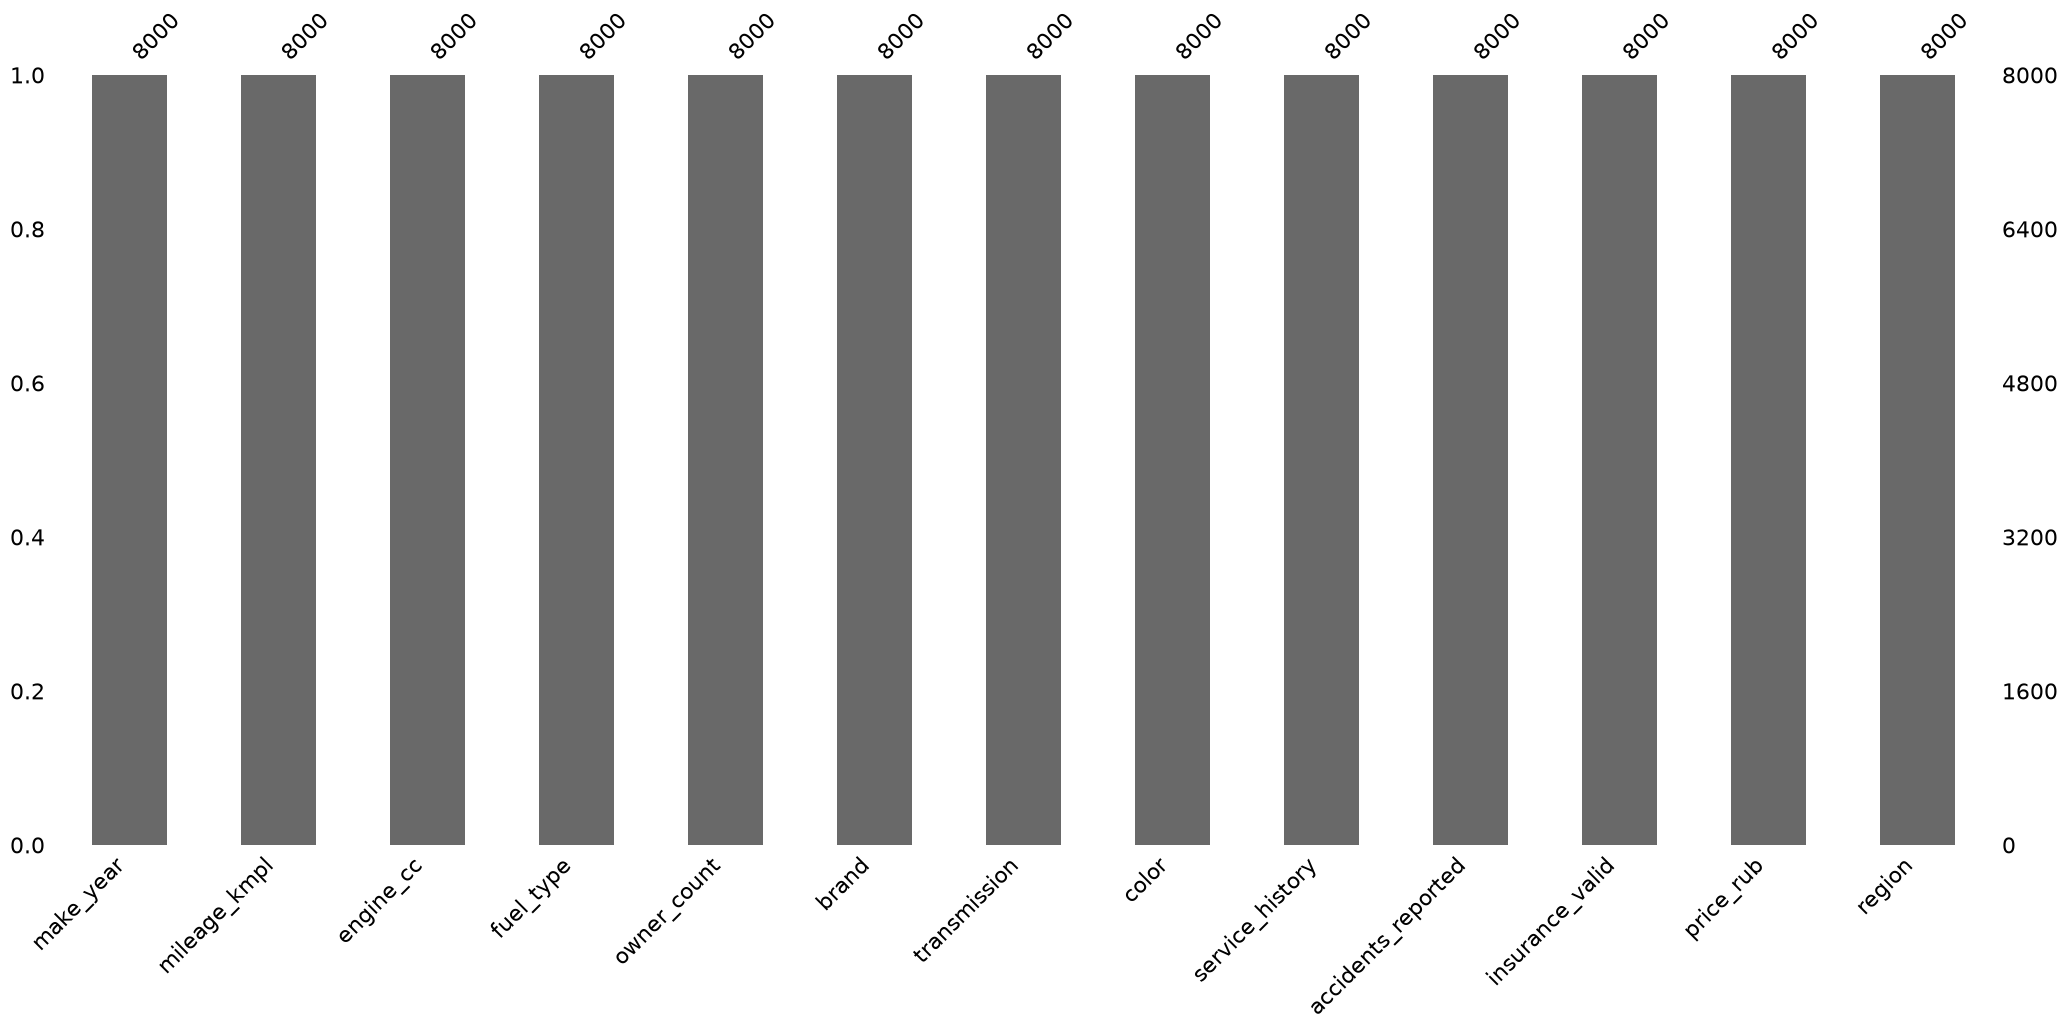

In [22]:
msno.bar(df_train)

<Axes: >

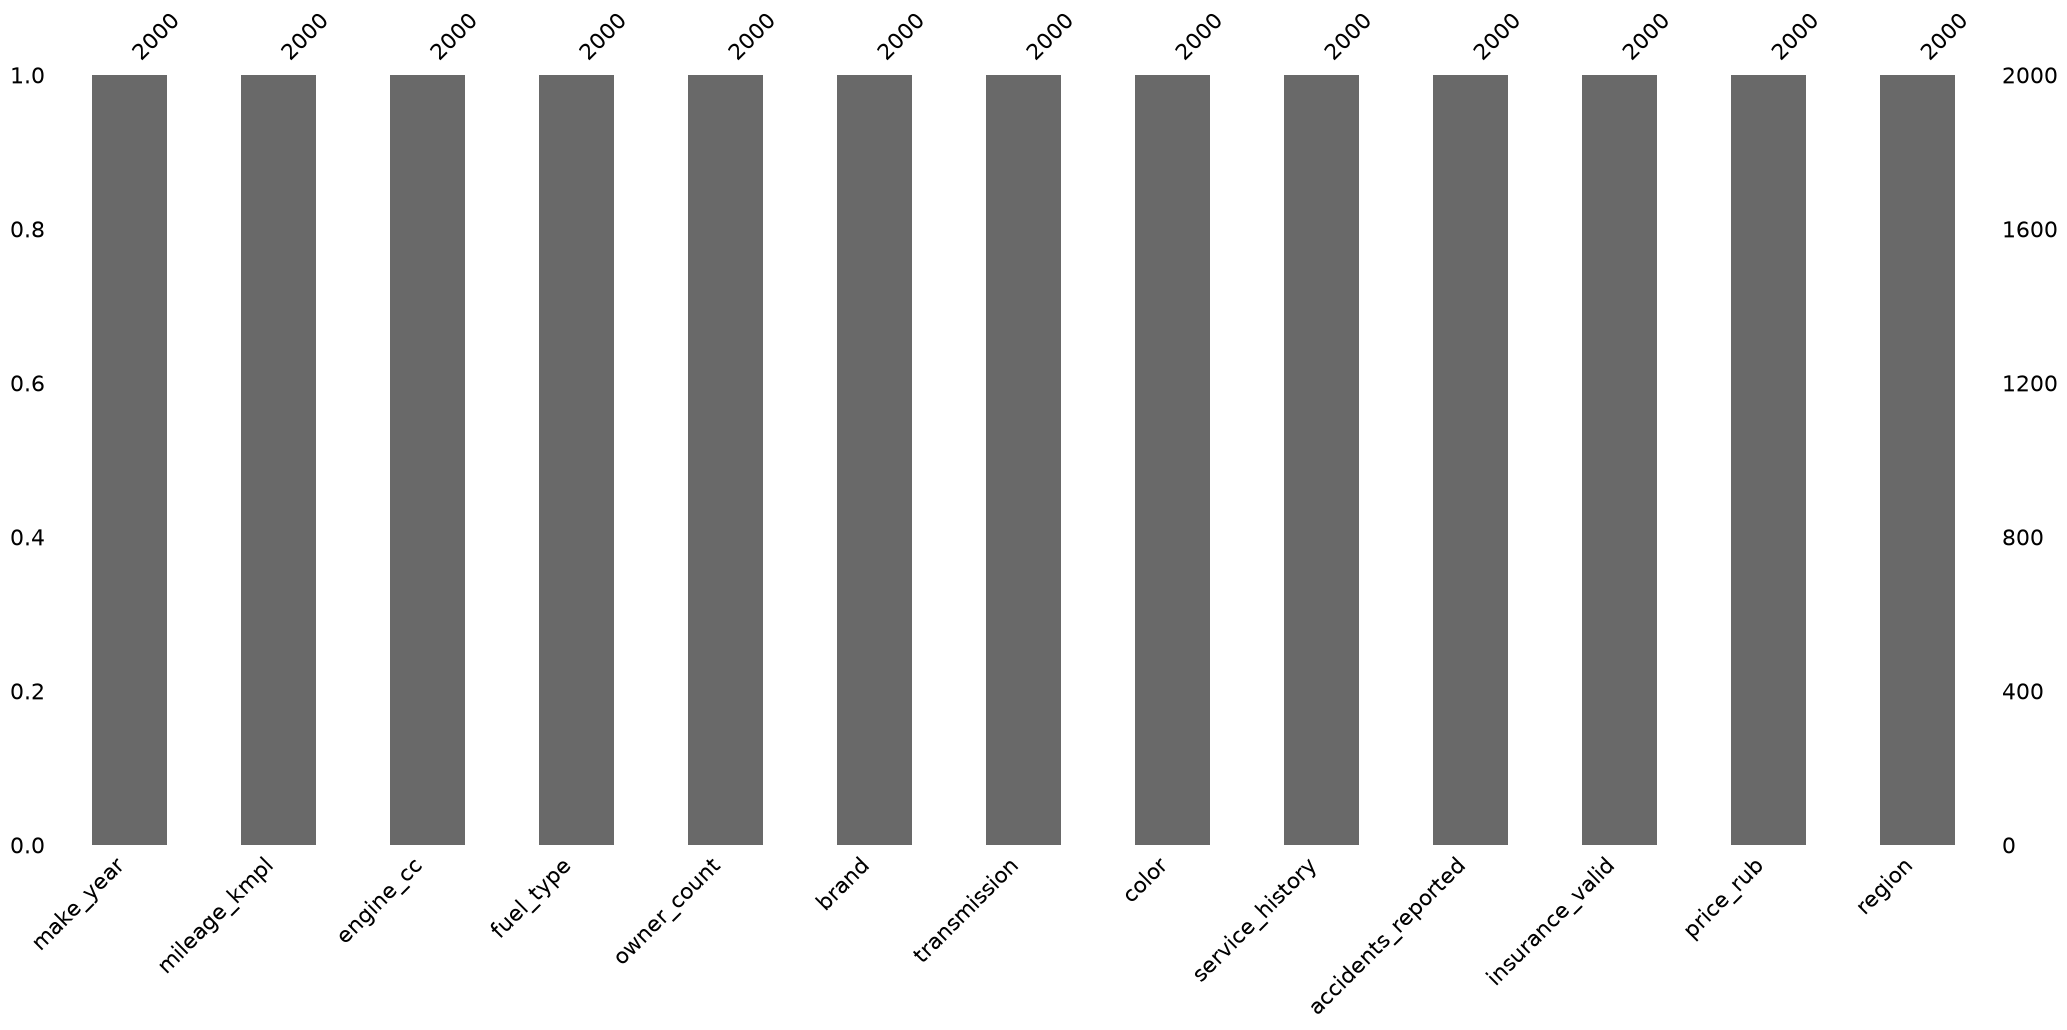

In [23]:
msno.bar(df_test)

<Axes: >

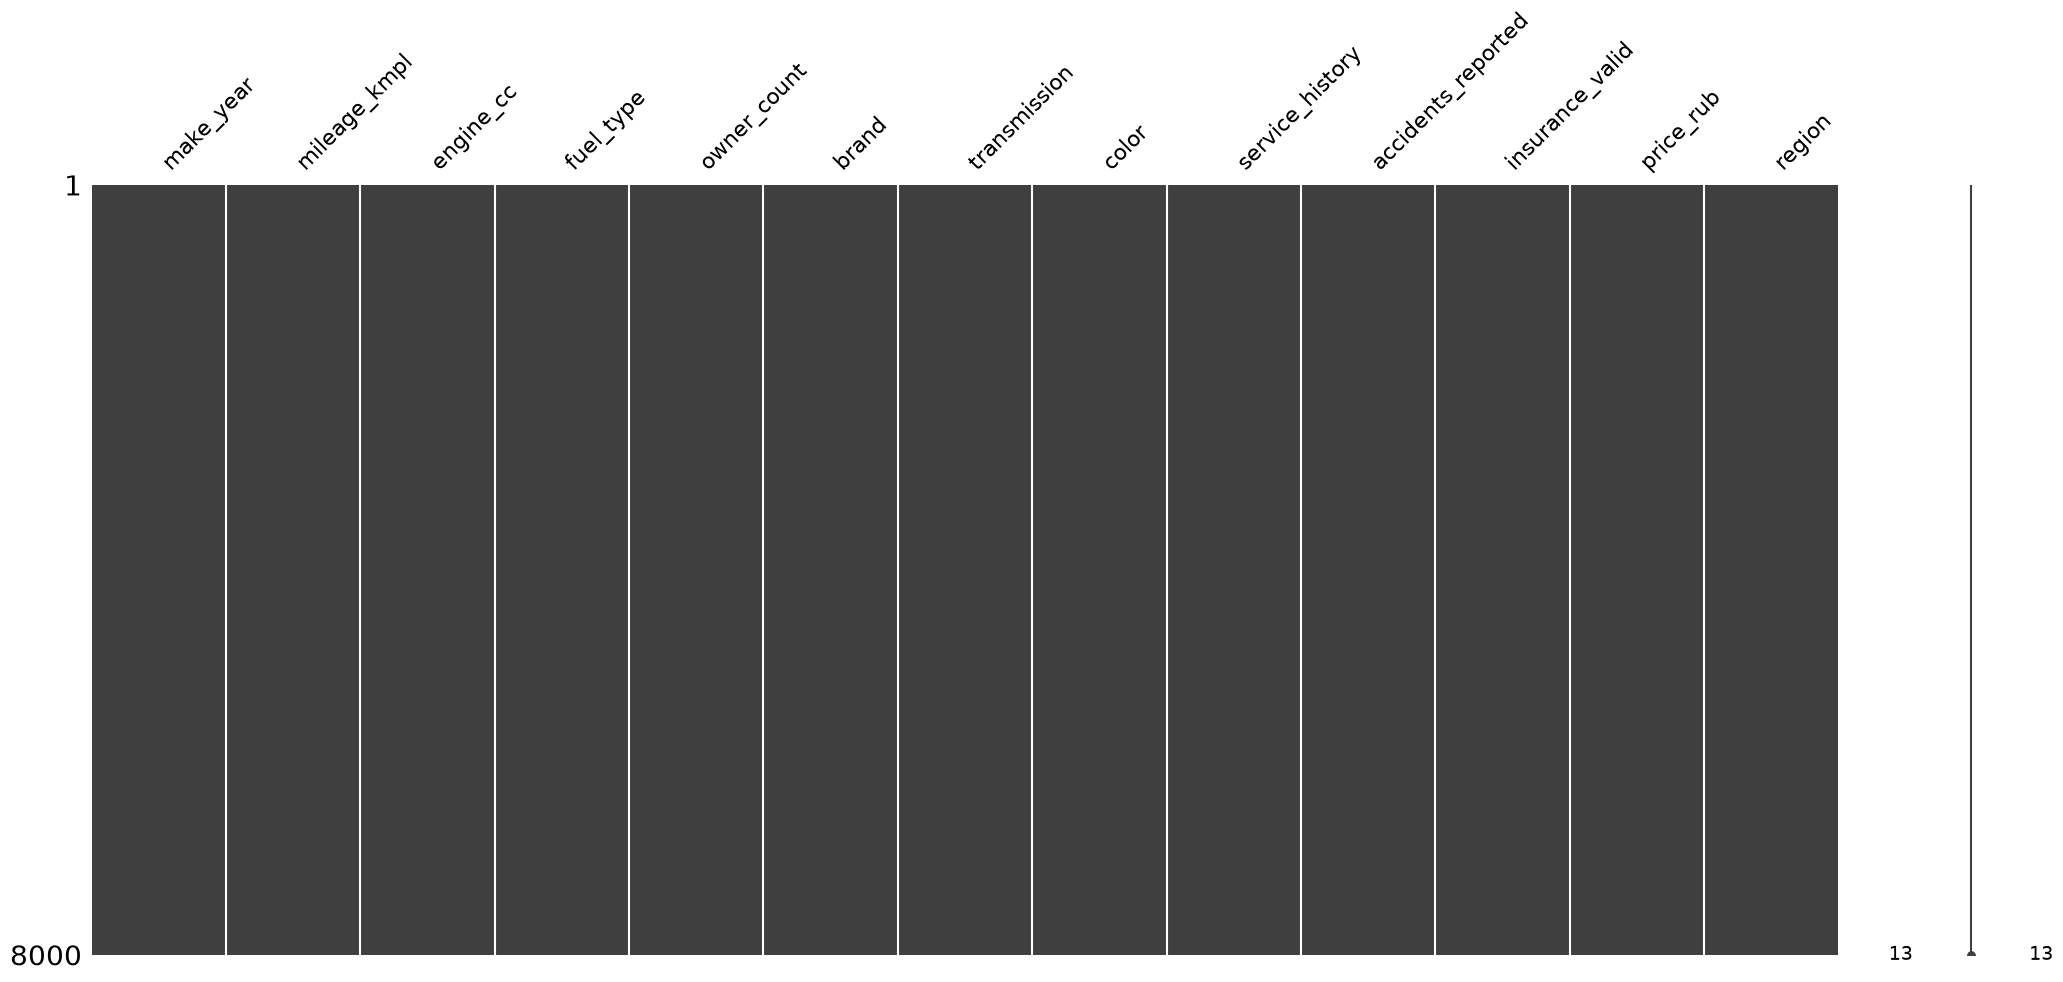

In [24]:
msno.matrix(df_train)

<Axes: >

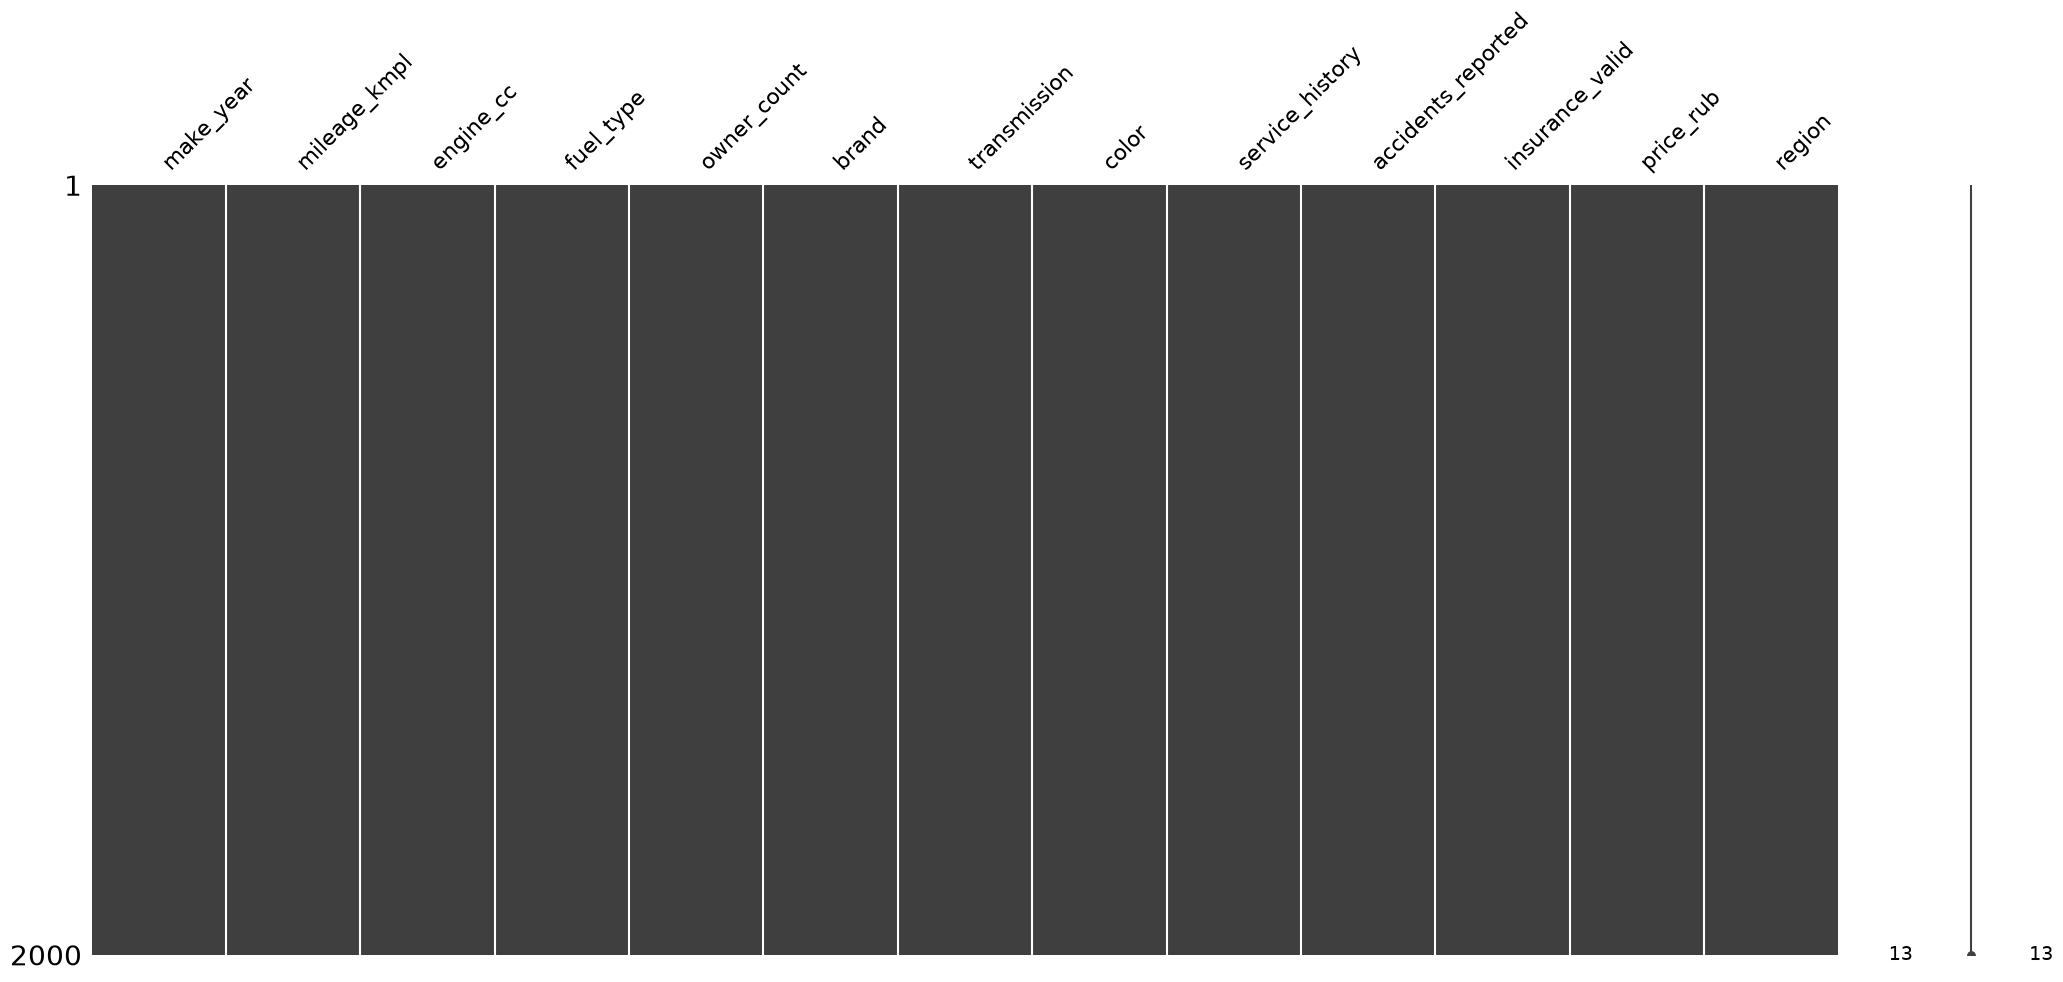

In [25]:
msno.matrix(df_test)

Пропуски в датасетах полностью отсутствуют.

### Анализ целевой переменной

In [26]:
target = 'price_rub'

Посмотрим статистику целевой переменной:

In [27]:
df_train[target].describe()

count                    8000.0
mean     683647.872124999994412
std      264923.498564331210218
min                     95000.0
25%                    493857.0
50%                    663866.0
75%                    855056.0
max                   1676525.0
Name: price_rub, dtype: Float64

По статистике видно, что после 3 квантиля присутствуют очень крупные выбросы, так что максимальное значение отличается от него аж в 2 раза. Из-за этого среднее значение будет довольно сильно увеличиваться.

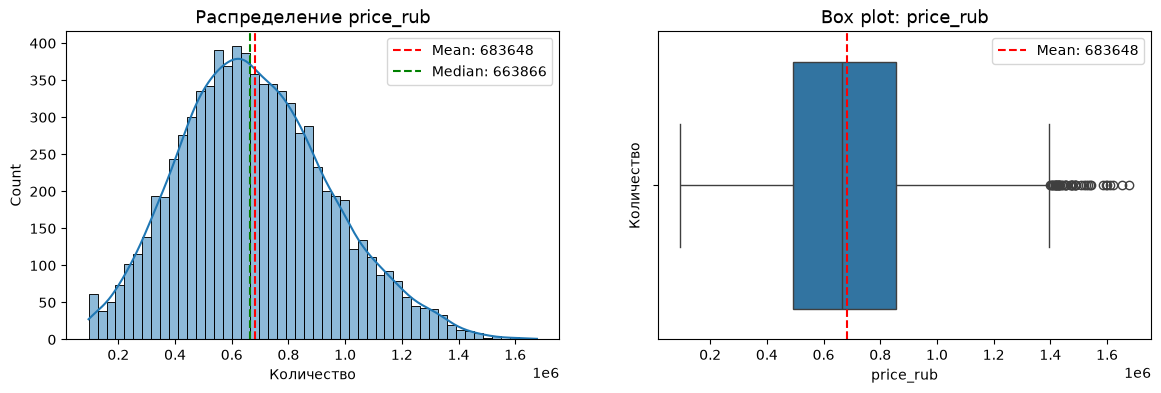

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))

sns.histplot(df_train[target], bins=50, kde=True,ax=axes[0])
axes[0].set_title('Распределение price_rub', fontsize=13)
axes[0].set_xlabel('Количество')
axes[0].axvline(df_train[target].mean(), color='red', linestyle='--',
                   label=f"Mean: {df_train[target].mean():.0f}")
axes[0].axvline(df_train[target].median(), color='green', linestyle='--',
                   label=f"Median: {df_train[target].median():.0f}")
axes[0].legend()

sns.boxplot(x=df_train[target], ax=axes[1])
axes[1].set_title('Box plot: price_rub', fontsize=13)
axes[1].set_ylabel('Количество')
axes[1].axvline(df_train[target].mean(), color='red', linestyle='--',
                   label=f"Mean: {df_train[target].mean():.0f}")
axes[1].legend()

Среднее значение и медиана почти совпадают, оно лишь немного больше нее. По гистограмме и боксплоту видно, что распределение немного скошенное и имеет хвост справа. **Проверим выброзы IQR методом:** 

In [29]:
Q1 = df_train[target].quantile(0.25)
Q3 = df_train[target].quantile(0.75)  
IQR = Q3 - Q1  

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

n_outliers = (df_train[target] > upper).sum()
print(f"Верхняя граница: {upper:.0f}")
print(f"Выбросов справа: {n_outliers} ({n_outliers/len(df_train)*100:.1f}%)")

Верхняя граница: 1396854
Выбросов справа: 45 (0.6%)


#### Выводы:

Целевая переменная `price_rub` — рыночная стоимость автомобиля в рублях — содержит 8 000 записей. Пропусков в целевой переменной нет.

**Распределение ЦП:**
- Распределение близко к нормальному с **лёгкой правосторонней скошенностью**: среднее значение (683 648 руб) лишь незначительно превышает медиану (663 866 руб), разница составляет около 3%. Пик гистограммы приходится на диапазон 500 000 – 800 000 рублей, а длинный правый хвост простирается до 1 676 525 рублей. Это означает, что большинство сделок совершается в среднем ценовом сегменте, но присутствует заметная доля дорогих автомобилей.
- Минимальное значение составляет 95 000 рублей — нулевых или аномально низких цен в данных нет, что соответствует рыночной реальности.
- Размах значений внушительный: от 95 000 до 1 676 525 рублей, стандартное отклонение составляет ~265 000 рублей. Это говорит о высокой вариативности цен в выборке.

**Выбросы (IQR-метод):**
- Верхняя граница «нормального» диапазона по методу межквартильного размаха составляет 1 396 854 рубля.
- Выбросами справа признаны **45 записей (0.6% от выборки)**. Это крайне малая доля.
- Такие значения интерпретируются не как ошибки измерения, а как ** автомобили премиум-сегмента**. 

**Итог:** Целевая переменная корректна, распределение практически симметричное с лёгким правым хвостом, выбросов критически мало и они имеют бизнес-смысл. 

### Анализ признаков

In [30]:
importance_data = []

num_cols = df_train.select_dtypes(include=['number', 'Int8', 'Int32', 'Float32', 'Int64', 'Float64']).columns.tolist()
cat_cols = df_train.select_dtypes(include=['category', 'object', 'string']).columns.tolist()

cols_to_exclude = ['price_rub', 'id']
num_cols = [col for col in num_cols if col not in cols_to_exclude]
cat_cols = [col for col in cat_cols if col not in cols_to_exclude]

df_train['price_group'] = pd.qcut(df_train['price_rub'], q=3, labels=['cheap', 'medium', 'expensive'])

for col in num_cols:
    med_cheap = df_train.loc[df_train['price_group'] == 'cheap', col].median()
    med_expensive = df_train.loc[df_train['price_group'] == 'expensive', col].median()
    
    if pd.notna(med_cheap) and pd.notna(med_expensive):
        diff = abs(med_expensive - med_cheap)
    else:
        diff = 0.0
    
    importance_data.append({
        'Признак': col,
        'Тип': 'Числовой',
        'Медиана (дешёвые)': round(med_cheap, 4) if pd.notna(med_cheap) else 0.0,
        'Медиана (дорогие)': round(med_expensive, 4) if pd.notna(med_expensive) else 0.0,
        'Разница': round(diff, 4)
    })

for col in cat_cols:
    mean_prices = df_train.groupby(col, observed=True)['price_rub'].mean().dropna()
    
    if len(mean_prices) > 1:
        diff = mean_prices.max() - mean_prices.min()
    else:
        diff = 0.0
    
    importance_data.append({
        'Признак': col,
        'Тип': 'Категориальный',
        'Медиана (дешёвые)': '—',
        'Медиана (дорогие)': '—',
        'Разница': round(diff, 4)
    })

importance_df = pd.DataFrame(importance_data)

high_thresh = importance_df['Разница'].quantile(0.66)
med_thresh = importance_df['Разница'].quantile(0.33)

def categorize(x):
    if x >= high_thresh: return 'Высокая'
    elif x >= med_thresh: return 'Средняя'
    else: return 'Низкая'

importance_df['Важность'] = importance_df['Разница'].apply(categorize)
importance_df = importance_df.sort_values('Разница', ascending=False).reset_index(drop=True)

importance_df

,Признак,Тип,Медиана (дешёвые),Медиана (дорогие),Разница,Важность
0,fuel_type,Категориальный,—,—,272684.654099999985192,Высокая
1,color,Категориальный,—,—,34535.972399999998743,Высокая
2,brand,Категориальный,—,—,27106.392299999999523,Высокая
3,region,Категориальный,—,—,14452.274600000000646,Высокая
4,service_history,Категориальный,—,—,9484.826499999999214,Средняя
5,transmission,Категориальный,—,—,3963.160699999999906,Средняя
6,engine_cc,Числовой,1200.0,3000.0,1800.000000000000000,Средняя
7,make_year,Числовой,2003.0,2014.0,11.000000000000000,Средняя
8,mileage_kmpl,Числовой,16.690000534057617,19.100000381469727,2.410000085830688,Низкая
9,owner_count,Числовой,4.0,2.0,2.000000000000000,Низкая


### Анализ категориальных признаков

In [31]:
category_cols = df_train.select_dtypes(include=['category']).columns.to_list()
print(f'Количество категориальных признаков: {len(category_cols)}')

for col in category_cols:
    n_unique = df_train[col].nunique()
    n_missing = df_train[col].isnull().sum()
    pct_missing = n_missing / len(df_train) * 100
    print(f"   {col:<15} уникальных: {n_unique}, пропусков: {n_missing}, % пропусков: {pct_missing:.2f}%")

Количество категориальных признаков: 7
   fuel_type       уникальных: 3, пропусков: 0, % пропусков: 0.00%
   brand           уникальных: 10, пропусков: 0, % пропусков: 0.00%
   transmission    уникальных: 2, пропусков: 0, % пропусков: 0.00%
   color           уникальных: 6, пропусков: 0, % пропусков: 0.00%
   service_history уникальных: 3, пропусков: 0, % пропусков: 0.00%
   region          уникальных: 6, пропусков: 0, % пропусков: 0.00%
   price_group     уникальных: 3, пропусков: 0, % пропусков: 0.00%


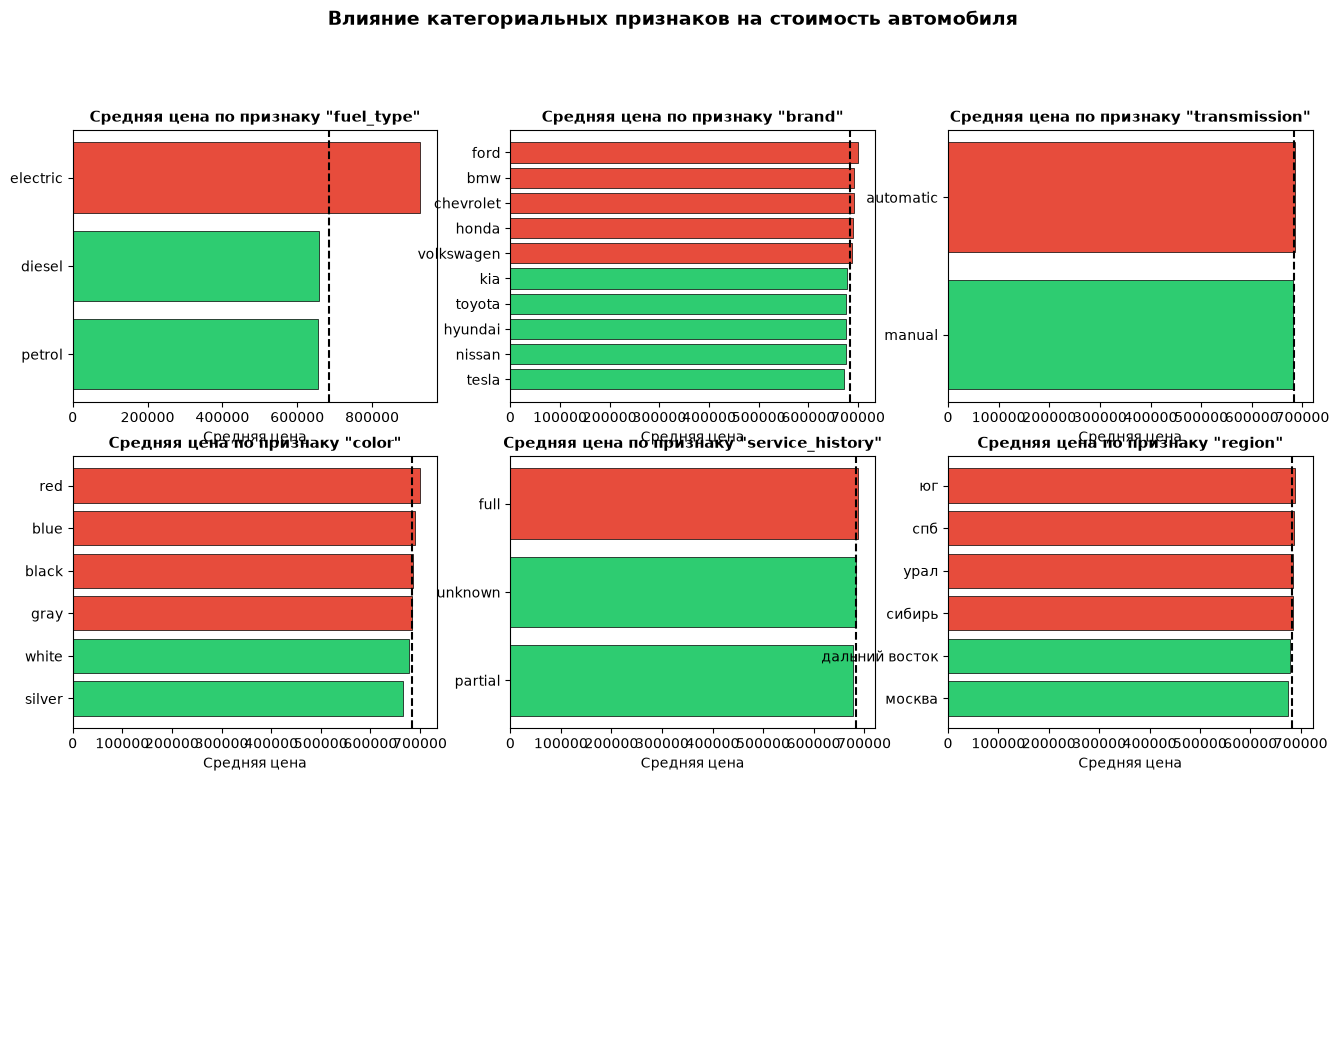

In [32]:
target = 'price_rub'

overall_mean = df_train[target].mean()

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ax = axes[i]
    
    mean_by_cat = df_train.groupby(col, observed=True)[target].mean().sort_values()
    
    colors = ['#2ecc71' if x <= overall_mean else '#e74c3c' for x in mean_by_cat]
    
    bars = ax.barh(mean_by_cat.index.astype(str), mean_by_cat.values, color=colors, edgecolor='black', linewidth=0.5)
    
    ax.axvline(overall_mean, color='black', linestyle='--', linewidth=1.5, label=f'Средняя: {overall_mean:,.0f} ₽')
    
    ax.set_title(f'Средняя цена по признаку "{col}"', fontsize=11, fontweight='bold')
    ax.set_xlabel('Средняя цена')

plt.suptitle('Влияние категориальных признаков на стоимость автомобиля', fontsize=14, fontweight='bold', y=0.98)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.show()

#### Выводы по влиянию категориальных признаков на цену:

Анализ средней стоимости выявил четкие ценовые паттерны:

1. **Главные драйверы цены:** `brand`, `fuel_type` и `service_history`. Электрокары значительно дороже массового сегмента, а наличие полной истории обслуживания (`full`) закономерно повышает стоимость авто.
2. **Марка (`brand`):** Демонстрирует максимальный разброс. Ford и BMW формируют верхний ценовой сегмент, тогда как массовые Kia, Toyota, Hyundai (и неожиданно Tesla, вероятно, из-за старых моделей с большим пробегом) находятся ниже средней цены.
3. **Трансмиссия:** `automatic` стабильно оценивается выше `manual`, что соответствует рыночному спросу на комфорт.
4. **Нестандартные паттерны:** Самые популярные цвета (`white`, `silver`) и регион `москва` оказались *ниже* средней цены. Это типично для рынков с огромным объемом предложений, где преобладают бюджетные, корпоративные или сильно подержанные авто.

Тк все признаки имеют не сильно большое количество категорий - до 10, будем использовать `One-Hot Encoding`.

### Генерация новых признаков

In [33]:
CURRENT_YEAR = 2026

df_train_fe = df_train.copy()
df_test_fe = df_test.copy()

# Возраст автомобиля
df_train_fe['car_age'] = CURRENT_YEAR - df_train_fe['make_year']
df_test_fe['car_age'] = CURRENT_YEAR - df_test_fe['make_year']

# Квадрат возраста
df_train_fe['car_age_sq'] = df_train_fe['car_age'] ** 2
df_test_fe['car_age_sq'] = df_test_fe['car_age'] ** 2

# Флаг "Новый автомобиль" (до 3 лет)
df_train_fe['is_new_car'] = (df_train_fe['car_age'] <= 3).astype('Int8')
df_test_fe['is_new_car'] = (df_test_fe['car_age'] <= 3).astype('Int8')

# Флаг "Старый автомобиль" (старше 15 лет)
df_train_fe['is_old_car'] = (df_train_fe['car_age'] >= 15).astype('Int8')
df_test_fe['is_old_car'] = (df_test_fe['car_age'] >= 15).astype('Int8')

# Объем двигателя на литр топлива
df_train_fe['engine_efficiency'] = df_train_fe['engine_cc'] / df_train_fe['mileage_kmpl']
df_test_fe['engine_efficiency'] = df_test_fe['engine_cc'] / df_test_fe['mileage_kmpl']

# Флаг отсутствия аварий
df_train_fe['no_accidents'] = (df_train_fe['accidents_reported'] == 0).astype('Int8')
df_test_fe['no_accidents'] = (df_test_fe['accidents_reported'] == 0).astype('Int8')

# Возраст * аварии
df_train_fe['age_accidents'] = df_train_fe['car_age'] * df_train_fe['accidents_reported']
df_test_fe['age_accidents'] = df_test_fe['car_age'] * df_test_fe['accidents_reported']

In [34]:
df_train_fe.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   make_year           8000 non-null   Int32   
 1   mileage_kmpl        8000 non-null   Float32 
 2   engine_cc           8000 non-null   Int32   
 3   fuel_type           8000 non-null   category
 4   owner_count         8000 non-null   Int32   
 5   brand               8000 non-null   category
 6   transmission        8000 non-null   category
 7   color               8000 non-null   category
 8   service_history     8000 non-null   category
 9   accidents_reported  8000 non-null   Int32   
 10  insurance_valid     8000 non-null   Int8    
 11  price_rub           8000 non-null   Int32   
 12  region              8000 non-null   category
 13  price_group         8000 non-null   category
 14  car_age             8000 non-null   Int32   
 15  car_age_sq          8000 non-null   Int32   
 16 

In [35]:
df_train_fe.head(5)

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region,price_group,car_age,car_age_sq,is_new_car,is_old_car,engine_efficiency,no_accidents,age_accidents
0,2002,9.699999809265137,1800,diesel,2,hyundai,manual,silver,partial,0,0,242073,урал,cheap,24,576,0,1,185.567013958154547,1,0
1,2004,16.100000381469727,1500,diesel,3,hyundai,manual,black,unknown,0,0,426029,москва,cheap,22,484,0,1,93.16769965585982,1,0
2,2005,10.510000228881836,5000,diesel,2,ford,manual,gray,full,0,0,727050,юг,medium,21,441,0,1,475.737382598701686,1,0
3,2019,14.270000457763672,2000,petrol,5,hyundai,manual,white,full,1,1,753168,дальний восток,medium,7,49,0,0,140.154165090575674,0,7
4,2015,21.719999313354492,1000,petrol,1,toyota,automatic,black,full,0,1,733390,сибирь,medium,11,121,0,0,46.040517109277822,1,0


### Распределение данных и анализ
**Построим боксплоты**

`Train`:

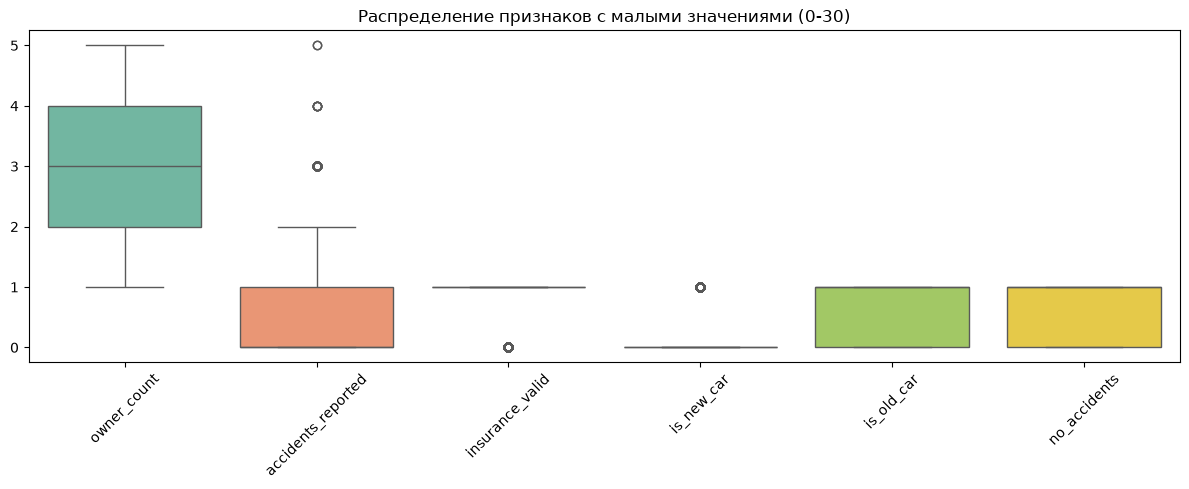

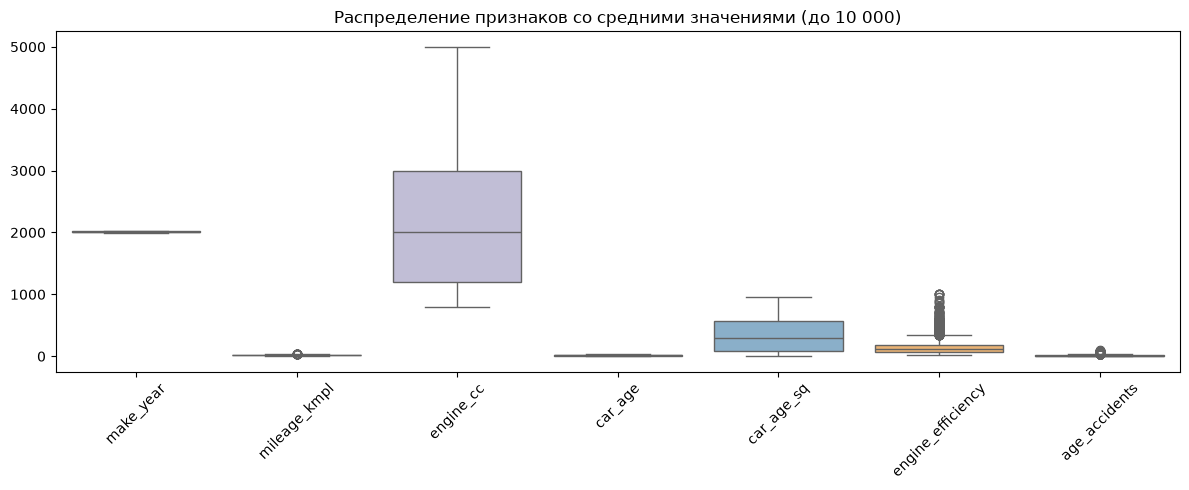

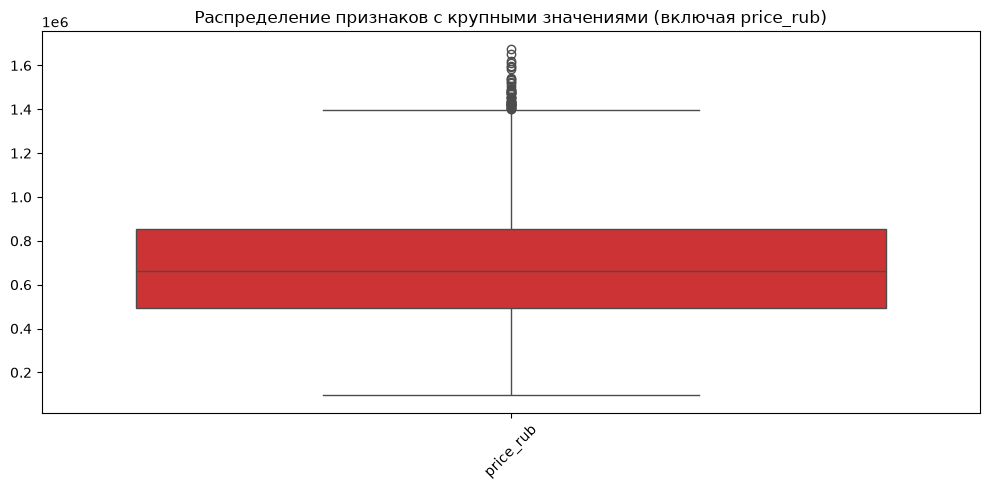

In [36]:
numeric_cols = df_train_fe.select_dtypes(include=['number', 'Int8', 'Float32', 'Float64', 'Int32']).columns.to_list()

small_cols = []
medium_cols = []
large_cols = []

for col in numeric_cols:
    max_val = df_train_fe[col].max()
    
    if max_val <= 30:  
        small_cols.append(col)
    elif max_val <= 10000:  
        medium_cols.append(col)
    else:   
        large_cols.append(col)
              
if small_cols:
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df_train_fe[small_cols], vert=True, palette='Set2')
    plt.title('Распределение признаков с малыми значениями (0-30)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

if medium_cols:
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df_train_fe[medium_cols],  vert=True, palette='Set3')
    plt.title('Распределение признаков со средними значениями (до 10 000)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

if large_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_train_fe[large_cols], vert=True, palette='Set1')
    plt.title('Распределение признаков с крупными значениями (включая price_rub)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

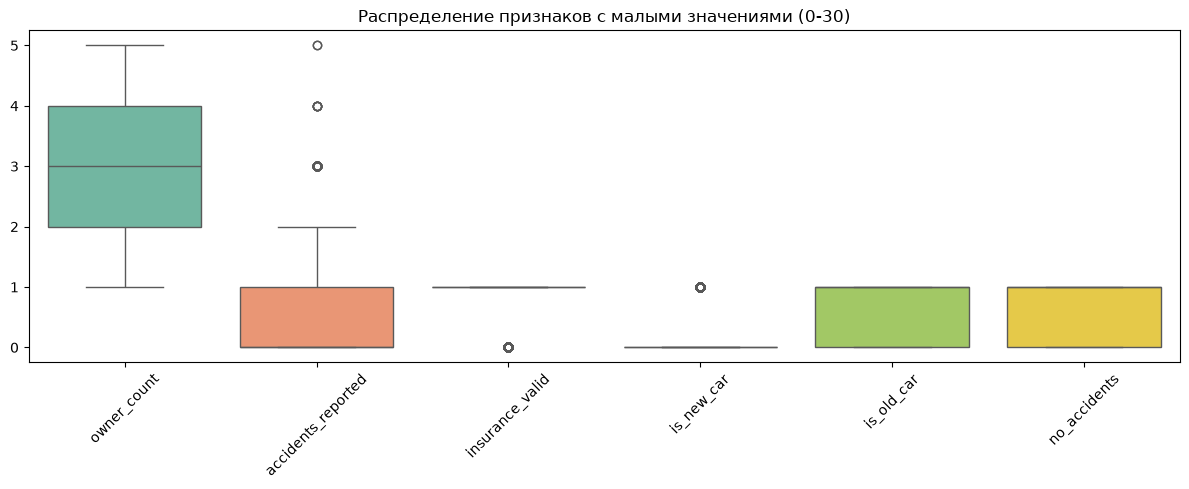

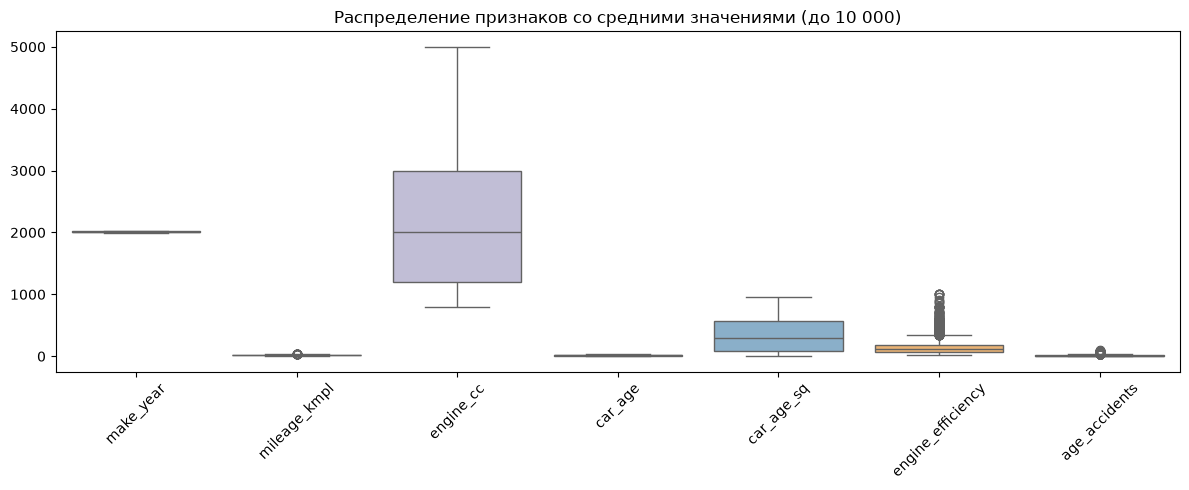

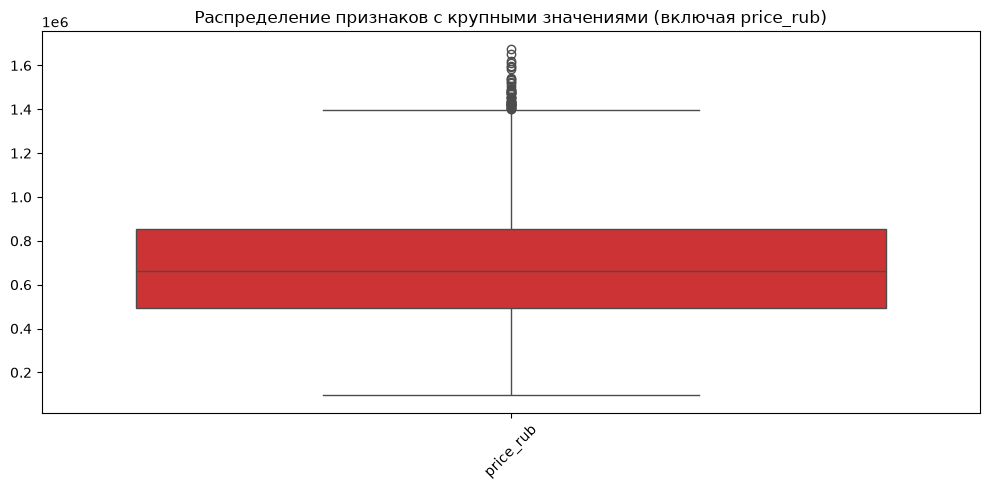

In [37]:
numeric_cols = df_test_fe.select_dtypes(include=['number', 'Int8', 'Float32', 'Float64', 'Int32']).columns.to_list()

small_cols = []
medium_cols = []
large_cols = []

for col in numeric_cols:
    max_val = df_train_fe[col].max()
    
    if max_val <= 30:  
        small_cols.append(col)
    elif max_val <= 10000:  
        medium_cols.append(col)
    else:   
        large_cols.append(col)
              
if small_cols:
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df_train_fe[small_cols], vert=True, palette='Set2')
    plt.title('Распределение признаков с малыми значениями (0-30)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

if medium_cols:
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df_train_fe[medium_cols],  vert=True, palette='Set3')
    plt.title('Распределение признаков со средними значениями (до 10 000)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

if large_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_train_fe[large_cols], vert=True, palette='Set1')
    plt.title('Распределение признаков с крупными значениями (включая price_rub)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

`Test`:

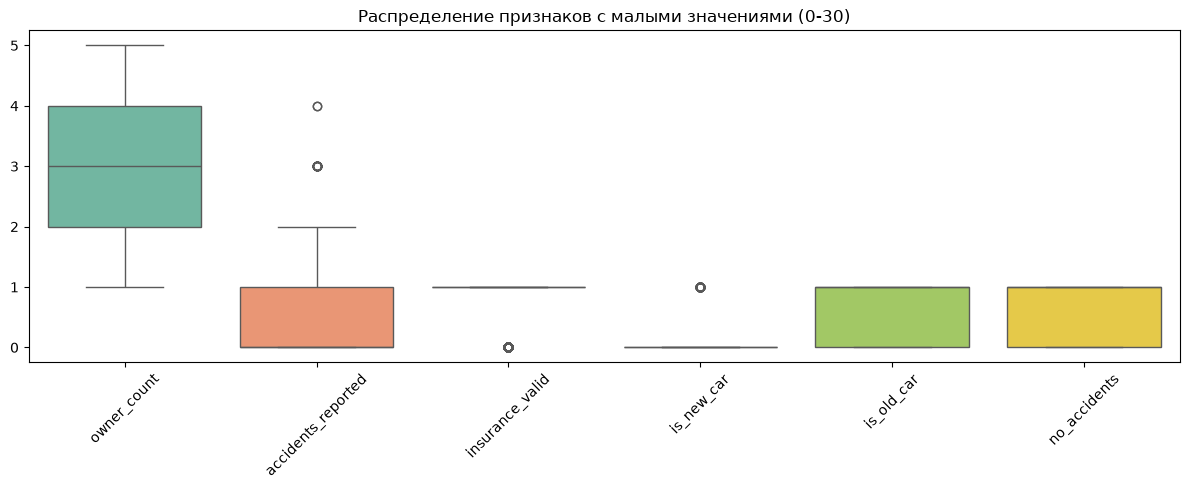

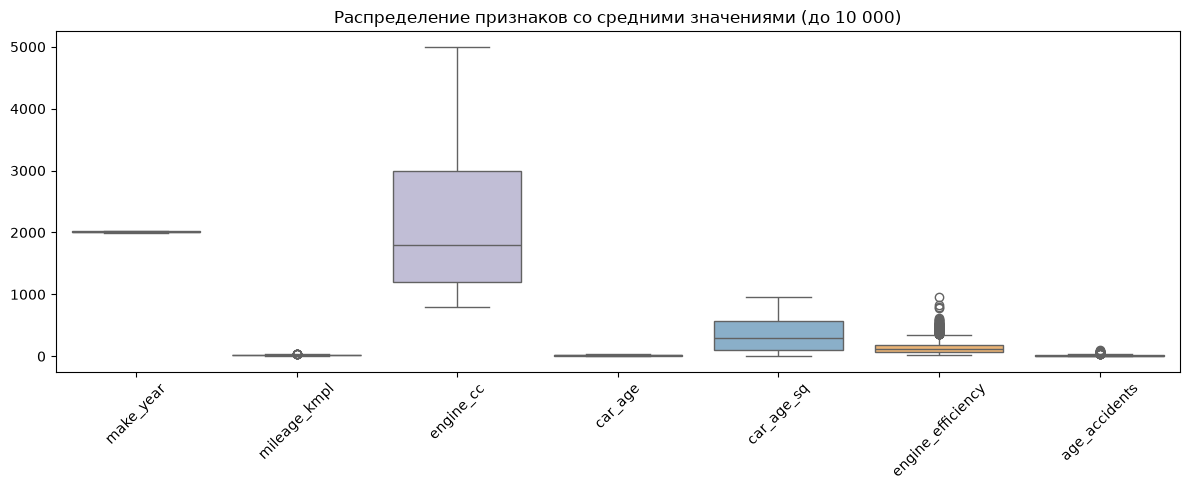

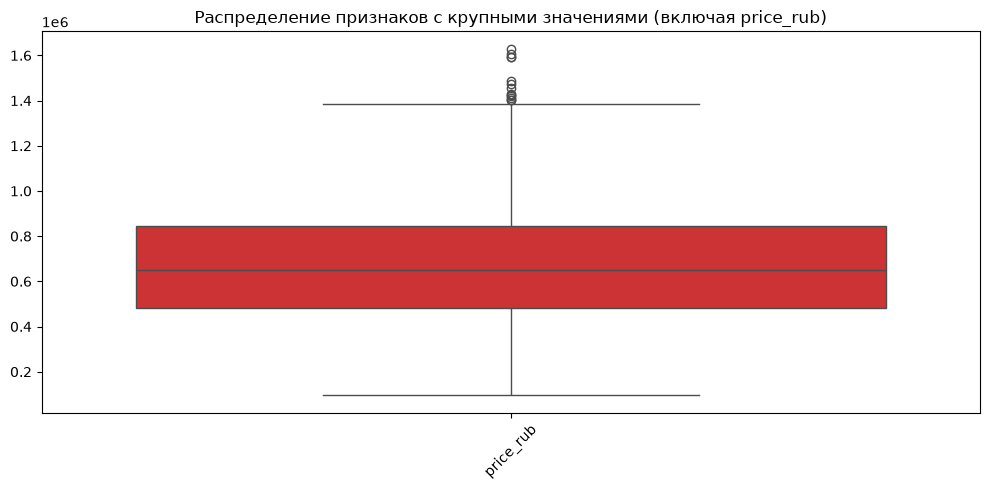

In [38]:
numeric_cols = df_test_fe.select_dtypes(include=['number', 'Int8', 'Float32', 'Float64', 'Int32']).columns.to_list()

small_cols = []
medium_cols = []
large_cols = []

for col in numeric_cols:
    max_val = df_test_fe[col].max()
    
    if max_val <= 30:  
        small_cols.append(col)
    elif max_val <= 10000:  
        medium_cols.append(col)
    else:   
        large_cols.append(col)
              
if small_cols:
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df_test_fe[small_cols], vert=True, palette='Set2')
    plt.title('Распределение признаков с малыми значениями (0-30)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

if medium_cols:
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df_test_fe[medium_cols],  vert=True, palette='Set3')
    plt.title('Распределение признаков со средними значениями (до 10 000)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

if large_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_test_fe[large_cols], vert=True, palette='Set1')
    plt.title('Распределение признаков с крупными значениями (включая price_rub)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Распределение в обучающем и тренировочном датасете одинаковое, посмотрим
**распределение значений проблемных признаков до преобразования:**

Text(0.5, 0, 'Значения')

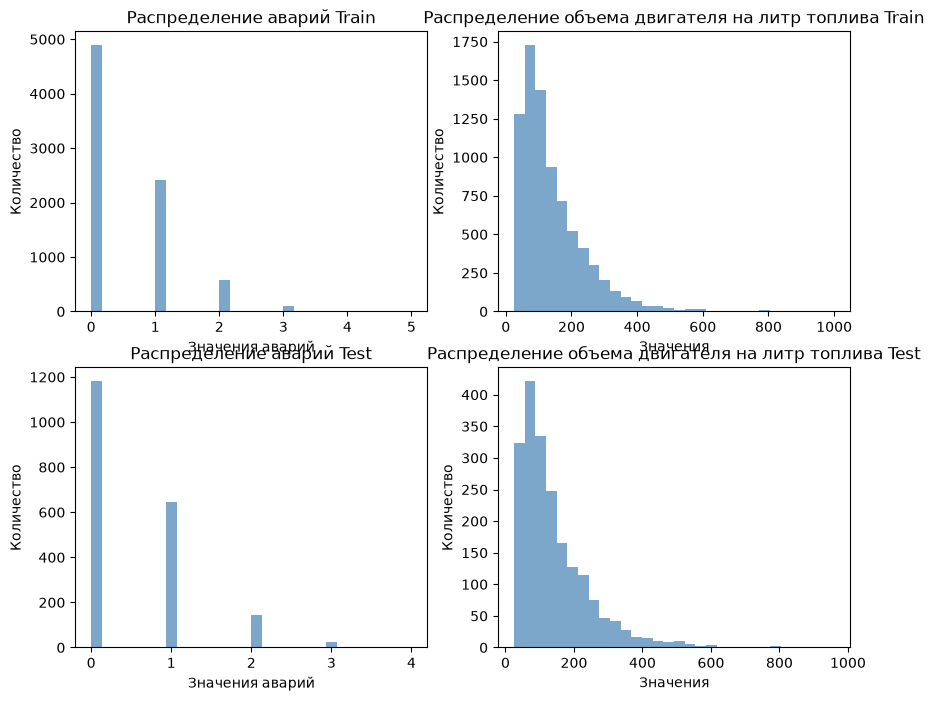

In [39]:
fig, axes = plt.subplots(2,2, figsize=(10,8))

axes[0][0].hist(df_train_fe['accidents_reported'], bins=30, color='steelblue', alpha=0.7)
axes[0][0].set_title('Распределение аварий Train')
axes[0][0].set_ylabel('Количество')
axes[0][0].set_xlabel('Значения аварий')

axes[0][1].hist(df_train_fe['engine_efficiency'], bins=30, color='steelblue', alpha=0.7)
axes[0][1].set_title('Распределение объема двигателя на литр топлива Train')
axes[0][1].set_ylabel('Количество')
axes[0][1].set_xlabel('Значения')

axes[1][0].hist(df_test_fe['accidents_reported'], bins=30, color='steelblue', alpha=0.7)
axes[1][0].set_title('Распределение аварий Test')
axes[1][0].set_ylabel('Количество')
axes[1][0].set_xlabel('Значения аварий')

axes[1][1].hist(df_test_fe['engine_efficiency'], bins=30, color='steelblue', alpha=0.7)
axes[1][1].set_title('Распределение объема двигателя на литр топлива Test')
axes[1][1].set_ylabel('Количество')
axes[1][1].set_xlabel('Значения')

**Распределение признаков:**
1. **`car_age` и `make_year`:** Распределение близкое к нормальному, без сильных перекосов. Признаки информативны и корректны.
2. **`insurance_valid` и `no_accidents`:** Распределение сильно скошено. Разброс минимальный, признаки бинарные. Сами по себе они могут быть слабоинформативны из-за дисбаланса, но полезны при создании нелинейных взаимодействий.
3. **Бинарные флаги (`is_new_car`, `is_old_car`):** Практически константы, выбросов нет. Эти признаки несут информацию только для специфических, редких сегментов рынка.
4. **Дискретные признаки (`owner_count`, `accidents_reported`):** Все имеют сильно скошенное распределение вправо:
   - Медианы близки к 1 и 0 соответственно.
   - Присутствуют редкие выбросы.
5. **`engine_efficiency` и `engine_cc`:** Имеют критическую правостороннюю асимметрию. Присутствует длинный "хвост" из автомобилей с огромным объемом двигателя или аномально высоким расходом топлива. Такие выбросы будут доминировать в модели и сильно искажать метрику RMSE.
6. **Разные масштабы признаков:** `mileage_kmpl` измеряется десятками, `engine_cc` — тысячами, а `price_rub` — сотнями тысяч. Без учета этого фактора модели, чувствительные к масштабу, будут придавать большее значение признакам с большими абсолютными значениями.

**Общие выводы по числовым признакам:**
1. **Масштабирование:** Поскольку основными алгоритмами в турнире являются градиентные бустинги (XGBoost, CatBoost, LightGBM), **жесткое масштабирование (Standard/RobustScaler) не является обязательным**, так как деревья решений инвариантны к масштабу признаков. Однако, если мы будем добавлять в турнир линейную регрессию LinearRegression для бейзлайна, для неё потребуется `RobustScaler` для устойчивости к выбросам.
2. **Логарифмирование:** Для сильно скошенных `engine_efficiency` имеет смысл применить логарифмирование (`log1p`). 

In [40]:
df_train_fe['engine_efficiency_log'] = np.log1p(df_train_fe['engine_efficiency'])
df_test_fe['engine_efficiency_log'] = np.log1p(df_test_fe['engine_efficiency'])

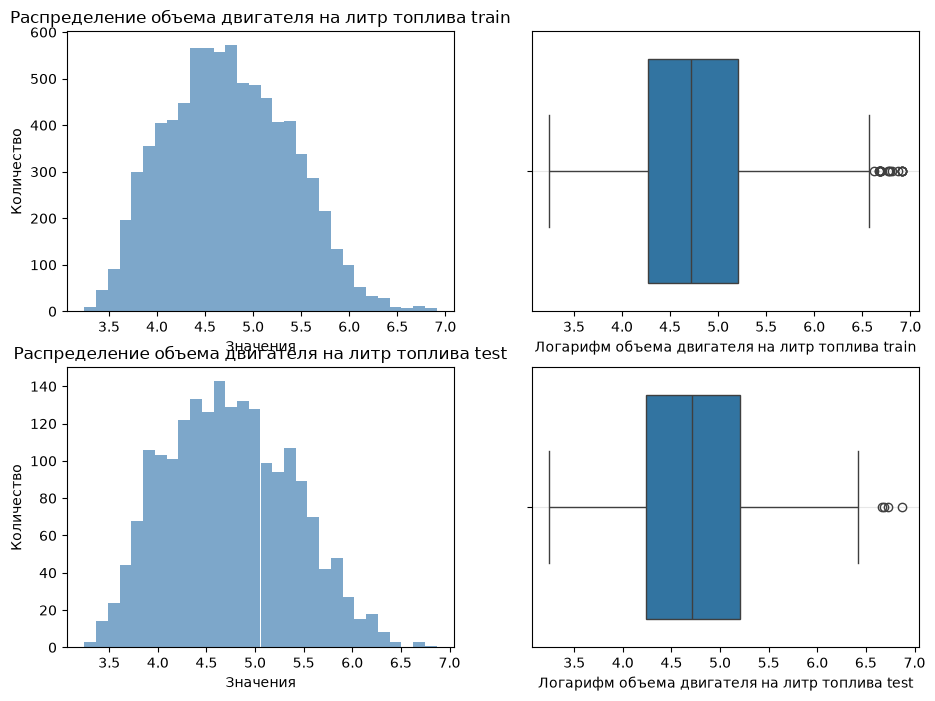

In [41]:
fig, axes = plt.subplots(2,2, figsize=(11,8))  

axes[0][0].hist(df_train_fe['engine_efficiency_log'], bins=30, color='steelblue', alpha=0.7)
axes[0][0].set_title('Распределение объема двигателя на литр топлива train')
axes[0][0].set_ylabel('Количество')
axes[0][0].set_xlabel('Значения')

sns.boxplot(x=df_train_fe['engine_efficiency_log'], ax=axes[0][1], vert=False)
axes[0][1].set_xlabel("Логарифм объема двигателя на литр топлива train")
axes[0][1].grid(alpha=0.3, axis='y')

axes[1][0].hist(df_test_fe['engine_efficiency_log'], bins=30, color='steelblue', alpha=0.7)
axes[1][0].set_title('Распределение объема двигателя на литр топлива test')
axes[1][0].set_ylabel('Количество')
axes[1][0].set_xlabel('Значения')

sns.boxplot(x=df_test_fe['engine_efficiency_log'], ax=axes[1][1], vert=False)
axes[1][1].set_xlabel("Логарифм объема двигателя на литр топлива test")
axes[1][1].grid(alpha=0.3, axis='y')

После сглаживание логарифмированием распределение стало более гладким, близким к нормальному. 

In [42]:
df_train_fe = df_train_fe.drop(columns=['engine_efficiency'])
df_test_fe = df_test_fe.drop(columns=['engine_efficiency'])

In [43]:
df_train_fe.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   make_year              8000 non-null   Int32   
 1   mileage_kmpl           8000 non-null   Float32 
 2   engine_cc              8000 non-null   Int32   
 3   fuel_type              8000 non-null   category
 4   owner_count            8000 non-null   Int32   
 5   brand                  8000 non-null   category
 6   transmission           8000 non-null   category
 7   color                  8000 non-null   category
 8   service_history        8000 non-null   category
 9   accidents_reported     8000 non-null   Int32   
 10  insurance_valid        8000 non-null   Int8    
 11  price_rub              8000 non-null   Int32   
 12  region                 8000 non-null   category
 13  price_group            8000 non-null   category
 14  car_age                8000 non-null   Int32   
 15

In [44]:
optimization(df_train_fe, ['engine_efficiency_log'], 'Float32')
optimization(df_test_fe, ['engine_efficiency_log'], 'Float32')

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region,car_age,car_age_sq,is_new_car,is_old_car,no_accidents,age_accidents,engine_efficiency_log
0,2015,12.090000152587891,5000,diesel,1,nissan,automatic,white,full,2,0,1213351,москва,11,121,0,0,0,22,6.027229785919189
1,2016,14.029999732971191,800,petrol,4,chevrolet,manual,white,partial,0,1,586881,дальний восток,10,100,0,0,1,0,4.060799121856689
2,2005,20.399999618530273,2000,petrol,1,kia,manual,blue,full,2,1,650752,сибирь,21,441,0,1,0,42,4.595515727996826
3,1996,25.090000152587891,800,diesel,3,volkswagen,manual,silver,full,0,1,320452,урал,30,900,0,1,1,0,3.493023157119751
4,1995,19.25,5000,diesel,5,hyundai,automatic,black,partial,0,0,694911,спб,31,961,0,1,1,0,5.563524723052979
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,2008,16.510000228881836,2500,petrol,4,tesla,automatic,gray,full,0,1,629476,москва,18,324,0,1,1,0,5.02666187286377
1996,2010,12.170000076293945,1500,petrol,2,toyota,manual,white,full,0,1,517497,урал,16,256,0,1,1,0,4.822327136993408
1997,2014,14.930000305175781,5000,electric,5,chevrolet,manual,red,unknown,0,1,1248892,сибирь,12,144,0,0,1,0,5.816802024841309
1998,2016,14.630000114440918,1000,electric,1,volkswagen,manual,gray,full,0,0,1083834,москва,10,100,0,0,1,0,4.239204883575439


#### Выводы
Распределение признаков на тренировочном и тестовом датасетах практически идентично.

**Распределение признаков:**
- Дискретные признаки имеют сильную правостороннюю скошенность с пиком на нулевых и единичных значениях — большинство автомобилей имеют 1-2 владельца и 0 зарегистрированных аварий.
- Непрерывные технические признаки (`engine_cc`, `engine_efficiency`) имеют критическую правостороннюю асимметрию с длинным хвостом — присутствуют автомобили с объёмом двигателя свыше 5000 и аномально высокой прожорливостью.
- Временные признаки (`make_year`, `car_age`) распределены симметрично, без выбросов и аномалий.

**Целевая переменная `price_rub`** имеет распределение, близкое к нормальному, с лёгким правым хвостом. Пик приходится на диапазон 500 000 – 800 000 рублей, максимальные значения уходят за 1.6 млн рублей. 

**Будет проводиться выбор между моделями `XGBoost`, `CatBoost`, `LightGBM` и `StackingRegressor`.** 
- Выбросы в целевой переменной (`price_rub`) и признаках (`engine_cc`, `engine_efficiency`) **крайне важны для бизнеса**, так как отражают премиум-сегмент.
- Все три модели градиентного бустинга **устойчивы к выбросам и не требуют масштабирования** признаков, так как деревья решений инвариантны к масштабу данных.
- Отдельно создадим паплайн с `RobustScaler`  для базовой модели - линейной регрессии и стекинга.
- Проведено логарифмирование `engine_efficiency`

### Корреляционный анализ между признаками и целевой переменной

In [45]:
df_train_fe.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   make_year              8000 non-null   Int32   
 1   mileage_kmpl           8000 non-null   Float32 
 2   engine_cc              8000 non-null   Int32   
 3   fuel_type              8000 non-null   category
 4   owner_count            8000 non-null   Int32   
 5   brand                  8000 non-null   category
 6   transmission           8000 non-null   category
 7   color                  8000 non-null   category
 8   service_history        8000 non-null   category
 9   accidents_reported     8000 non-null   Int32   
 10  insurance_valid        8000 non-null   Int8    
 11  price_rub              8000 non-null   Int32   
 12  region                 8000 non-null   category
 13  price_group            8000 non-null   category
 14  car_age                8000 non-null   Int32   
 15

Для начала визуализируем тепловую карту **корреляции между всеми признаками**: 

Непрерывные признаки: ['mileage_kmpl', 'engine_efficiency_log']


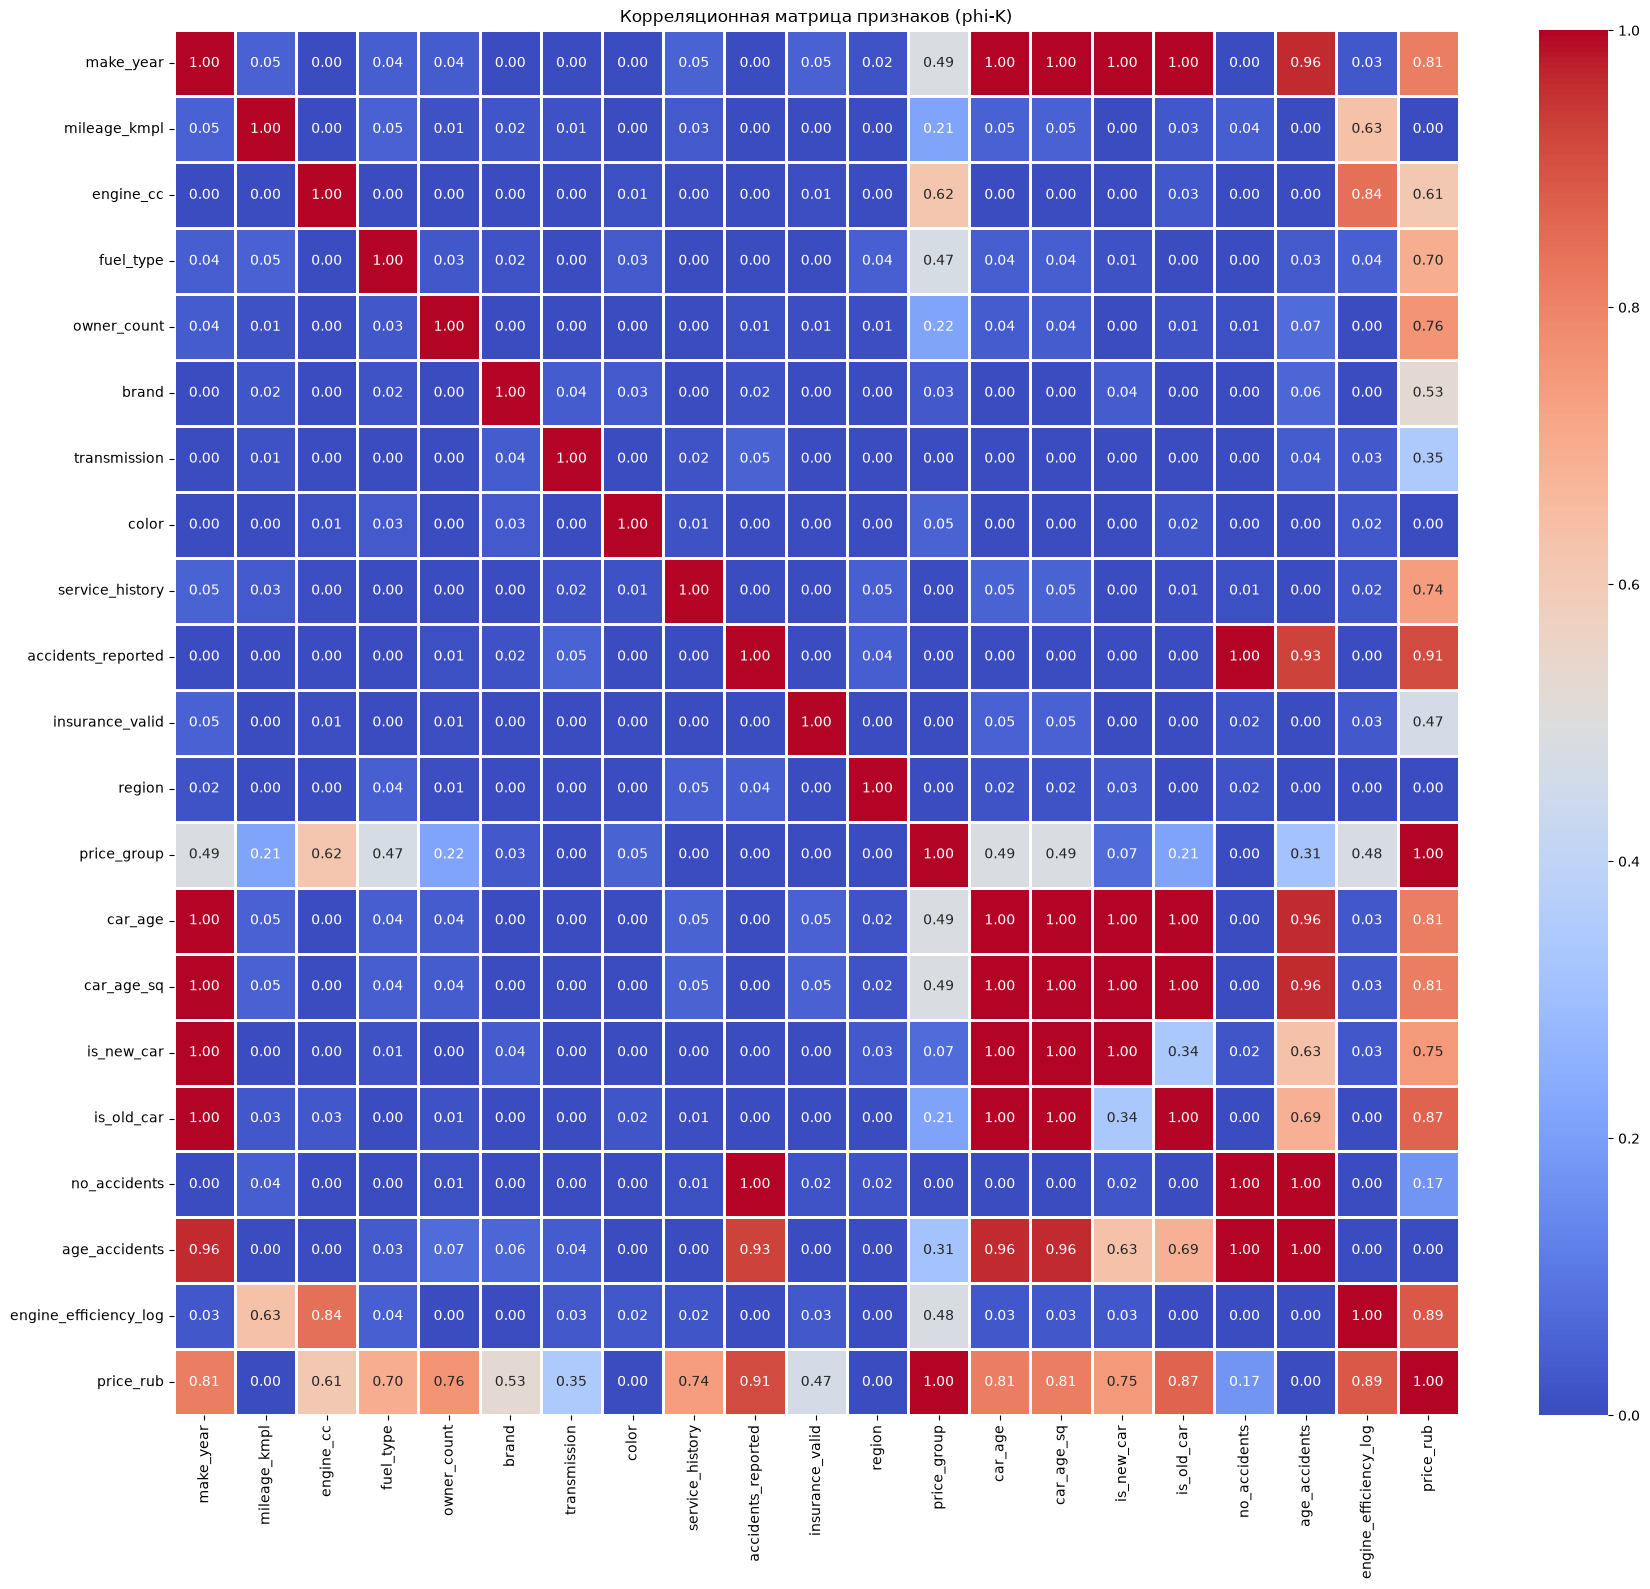

In [46]:
df_for_phik = df_train_fe.drop(columns=['price_rub']).copy()
df_for_phik['price_rub'] = df_train_fe['price_rub']

for col in df_for_phik.columns:
    dtype_str = str(df_for_phik[col].dtype)
    if dtype_str in ['Float32', 'Float64']:
        df_for_phik[col] = df_for_phik[col].to_numpy(dtype='float32', na_value=np.nan)
    elif dtype_str in ['Int8', 'Int16', 'Int32']:
        df_for_phik[col] = df_for_phik[col].to_numpy(dtype='int32', na_value=-1)

cat_cols = df_for_phik.select_dtypes(include=['category', 'object']).columns.tolist()
for col in cat_cols:
    if df_for_phik[col].dtype.name == 'category':
        df_for_phik[col] = df_for_phik[col].cat.codes.astype('int32')
    else:
        df_for_phik[col] = df_for_phik[col].astype('category').cat.codes.astype('int32')

interval_cols = df_for_phik.select_dtypes(
    include=['Float32', 'Float64']
).columns.tolist()

print('Непрерывные признаки:', interval_cols)

phik_result = phik_matrix(df_for_phik, interval_cols=interval_cols, njobs=1)

plt.figure(figsize=(18, 16))
sns.heatmap(phik_result, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=1, vmin=0, vmax=1)
plt.title('Корреляционная матрица признаков (phi-K)')
plt.tight_layout()
plt.show()

- В данных присутствует мультиколлинеарность:
    1) `make_year` – `car_age` (1.00) – полная линейная зависимость (год выпуска и возраст авто). Необходимо удалить `make_year`, оставить `car_age` как более интерпретируемый для бизнеса признак.
    2) `car_age` – `car_age_sq` (1.00) – квадратичное преобразование полностью повторяет исходный признак. Для деревьев решений это избыточно, следует удалить `car_age_sq`.
    3) `accidents_reported` – `no_accidents` (1.00) – полная инверсия одного и того же факта. Оставить `accidents_reported` (несёт больше информации), удалить `no_accidents`.
    4) `accidents_reported` – `age_accidents` (0.93) – сильная зависимость, так как `age_accidents` = `car_age` × `accidents_reported`. Оставить `age_accidents`, сырой `accidents_reported` удалить.
    5) `is_new_car` – `is_old_car` (1.00) – судя по матрице, признаки полностью скоррелированы (вероятно, из-за специфики кодирования). Оставить один, например `is_old_car`, так как он сильнее связан с ценой (0.87 против 0.75).
    6) `engine_efficiency_log` – `engine_cc` (0.84) – высокая корреляция, так как эффективность производна от объёма двигателя. Оставить `engine_efficiency_log`, сырой `engine_cc` удалить.
    7) `price_group` – `price_rub` (1.00) – признак создан на основе таргета, это утечка данных. **Обязательно удалить `price_group`** перед обучением модели.
    8) `color` – `price_rub` (0.00) и `region` – `price_rub` (0.00) – признаки практически не коррелируют с целевой переменной. Это не мультиколлинеарность, но низкая информативность — стоит проверить их важность после обучения базовой модели и, возможно, исключить.

**Построим столбчатые диаграммы для визуализации связи признаков с целевой переменной:**

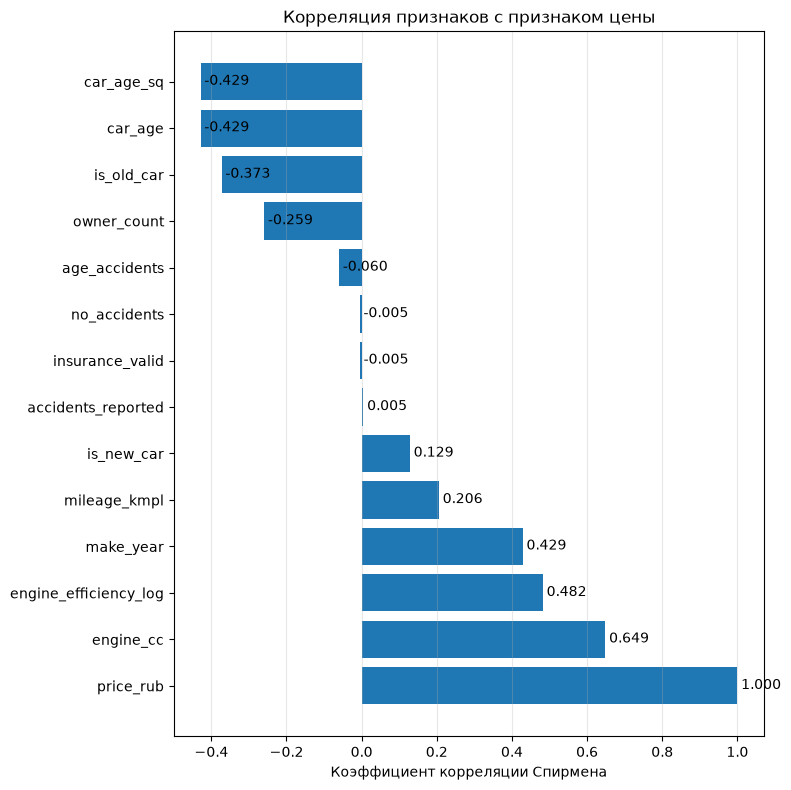

,Корреляция Спирмена с признаком цены
engine_cc,0.648558175209786
engine_efficiency_log,0.482336315323403
make_year,0.428694379939748
mileage_kmpl,0.205730469631651
is_new_car,0.128503920917544
accidents_reported,0.004669433786902
insurance_valid,-0.004873538203466
no_accidents,-0.005226506988482
age_accidents,-0.060121527256049
owner_count,-0.259252464492809


In [47]:
target_col = 'price_rub' 
corr_df = df_train_fe.drop(columns=['price_rub']).select_dtypes(include='number')
corr_df[target_col] = df_train_fe[target_col]
correlation = corr_df.corr(method='spearman')[target_col].sort_values(ascending=False)

plt.figure(figsize=(8,8))
plt.barh(correlation.index, correlation.values)
plt.xlabel('Коэффициент корреляции Спирмена')
plt.title('Корреляция признаков с признаком цены')
plt.grid(axis='x', alpha=0.3)

for i, (feat, corr) in enumerate(correlation.items()):
    plt.text(corr + 0.01, i+0.01, f'{corr:.3f}', va='center', fontsize=10)
  
plt.tight_layout()
plt.show()

corr_frame = (
    correlation
    .to_frame(name='Корреляция Спирмена с признаком цены')
    .drop(target_col)
)
corr_frame

#### Выводы
1. **Связь признаков с целевой переменной `price_rub`**:
    - Сильные положительные драйверы цены:
        - `engine_cc` (0.649) — объём двигателя является главным числовым предиктором стоимости. Чем мощнее мотор, тем дороже автомобиль.
        - `engine_efficiency_log` (0.482) — логарифмированная эффективность двигателя также сильно коррелирует с ценой.
        - `make_year` (0.429) — чем свежее автомобиль, тем он дороже.
    - Сильные отрицательные драйверы (удешевляют авто):
        - `car_age` и `car_age_sq` (-0.429) — возраст автомобиля снижает цену (зеркальное отражение make_year).
        - `is_old_car` (-0.373) — флаг "старше 15 лет" значительно удешевляет автомобиль.
        - `owner_count` (-0.259) — чем больше владельцев было у авто, тем ниже его цена.

2. **Выявлена мультиколлинеаность между признаками**. В связи с этим требуется удалить признаки: `make_year`, `car_age_sq`, `no_accidents`, `is_new_car`, `accidents_reported`. `engine_efficiency_log` и `engine_cc` обладают очень высокой важностью, хоть и имеют высокую мультиколлниеарность. Один признак дает информацию только о мощности двигателя, второй, дополнительно о расходе на километраж. Оставим оба этих признака, посмотрим на них в `feature_importance`

3. **Утечка данных**: `price_group` полнстью коррелирует с ЦП. Удалим его.

In [48]:
cols_to_drop = [
    'price_group', 'make_year', 'car_age_sq', 
    'no_accidents', 'is_new_car', 'accidents_reported'
]

df_train_final = df_train_fe.drop(columns=cols_to_drop, errors='ignore')
df_test_final = df_test_fe.drop(columns=cols_to_drop, errors='ignore')

In [49]:
df_train_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   mileage_kmpl           8000 non-null   Float32 
 1   engine_cc              8000 non-null   Int32   
 2   fuel_type              8000 non-null   category
 3   owner_count            8000 non-null   Int32   
 4   brand                  8000 non-null   category
 5   transmission           8000 non-null   category
 6   color                  8000 non-null   category
 7   service_history        8000 non-null   category
 8   insurance_valid        8000 non-null   Int8    
 9   price_rub              8000 non-null   Int32   
 10  region                 8000 non-null   category
 11  car_age                8000 non-null   Int32   
 12  is_old_car             8000 non-null   Int8    
 13  age_accidents          8000 non-null   Int32   
 14  engine_efficiency_log  8000 non-null   Float32 
dty

In [50]:
df_test_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   mileage_kmpl           2000 non-null   Float32 
 1   engine_cc              2000 non-null   Int32   
 2   fuel_type              2000 non-null   category
 3   owner_count            2000 non-null   Int32   
 4   brand                  2000 non-null   category
 5   transmission           2000 non-null   category
 6   color                  2000 non-null   category
 7   service_history        2000 non-null   category
 8   insurance_valid        2000 non-null   Int8    
 9   price_rub              2000 non-null   Int32   
 10  region                 2000 non-null   category
 11  car_age                2000 non-null   Int32   
 12  is_old_car             2000 non-null   Int8    
 13  age_accidents          2000 non-null   Int32   
 14  engine_efficiency_log  2000 non-null   Float32 
dty

### Вывод

Обучающая выборка содержит **8 000 записей**, тестовая — **2 000 записей**, по 15 исходных признаков. Распределения признаков в обеих выборках практически идентичны, сдвига распределений не обнаружено, что гарантирует корректную работу модели на тестовых данных.


**1. Пропуски и дубликаты:**
    Пропуски в данных **полностью отсутствуют** во всех признаках — это значительно упрощает предобработку. Полных и логических дубликатов также не обнаружено: каждый автомобиль представлен единственной записью, риск искусственного «раздувания» выборки отсутствует.

**2. Целевая переменная `price_rub`:**
    Распределение близко к нормальному с лёгкой правосторонней скошенностью: среднее (683 648 руб) лишь на 3% превышает медиану (663 866 руб). Пик приходится на диапазон 500 000 – 800 000 рублей, правый хвост простирается до 1 676 525 рублей. Выбросов по IQR-методу всего **45 записей (0.6%)** — это автомобили премиум-сегмента, удалять их не нужно, так как они несут важную информацию о верхней границе рынка.
    

**3. Информативность признаков:**
*Доминирующие признаки (высокая важность):*
- **`fuel_type`** — тип топлива является сильнейшим дискриминатором цены. Электромобили значительно дороже массового сегмента.
- **`brand`** — марка автомобиля ключевой фактор. Ford и BMW формируют верхний ценовой сегмент, массовые Kia, Toyota, Hyundai — нижний.
- **`color`** — популярные цвета (чёрный, белый, серый) парадоксально дешевле нестандартных (красный, синий), что связано с преобладанием бюджетных авто в популярных цветах.
- **`region`** — регион продажи влияет на цену из-за различий в локальном спросе и логистике.

*Числовые драйверы (по корреляции Спирмена):*
- **`engine_cc`** (0.649) — объём двигателя главный числовой предиктор стоимости.
- **`engine_efficiency_log`** (0.482) — логарифмированная эффективность двигателя.
- **`make_year` / `car_age`** (+-0.429) — чем свежее автомобиль, тем дороже.
- **`is_old_car`** (-0.373) — флаг «старше 15 лет» значительно удешевляет авто.
- **`owner_count`** (-0.259) — чем больше владельцев, тем ниже цена.

**4. Генерация признаков:**
Создано **8 новых признаков** на основе предметной логики автомобильного рынка:
- **Временные:** `car_age` (возраст авто), `car_age_sq` (квадрат возраста для учёта нелинейной амортизации), `is_new_car` (до 3 лет), `is_old_car` (старше 15 лет).
- **Технические:** `engine_efficiency` и его логарифм `engine_efficiency_log` (отношение объёма двигателя к расходу топлива — «прожорливость»). Логарифмирование сгладило критическую правостороннюю асимметрию, сделав распределение близким к нормальному.
- **История и состояние:** `no_accidents` (флаг отсутствия аварий), `age_accidents` (возраст × аварии — накопленный износ).

**5. Корреляционный анализ и мультиколлинеарность:**
*Выявленная мультиколлинеарность (требует удаления):*
1. `make_year` - `car_age` (1.00) — полная линейная зависимость
2. `car_age` - `car_age_sq` (1.00) — квадратичное преобразование избыточно для деревьев.
3. `accidents_reported` - `no_accidents` (1.00) — полная инверсия
4. `accidents_reported` - `age_accidents` (0.93) — сильная зависимость.
5. `is_new_car` - `is_old_car` (1.00) — оставлен `is_old_car` (сильнее связан с ценой: -0.373 против 0.129).

*Утечка данных:*
- `price_group` - `price_rub` (1.00) — признак создан на основе таргета. **Обязательно удалён** перед обучением.

---
## Предобработка данных
### Разделение данных на выборки
Разделим обучающие в пропорции 70/30. 70 - тренировочная, 30 - валидационная.

In [51]:
X_temp = df_train_final.drop(columns=['price_rub'])
y_temp = df_train_final['price_rub']

X_test = df_test_final.drop(columns=['price_rub'])
y_test = df_test_final['price_rub']

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.3, shuffle=True, random_state=42
)

print(f"Train: {len(X_train)} строк")
print(f"Val: {len(X_val)} строк")
print(f"Test: {len(X_test)} строк")

Train: 5600 строк
Val: 2400 строк
Test: 2000 строк


In [52]:
y_stats = pd.DataFrame({
    'Train': y_train.describe(),
    'Val': y_val.describe(),
    'Test': y_test.describe()
})

print(f'Стастистика целевой переменной по выборкам: ')
y_stats.style.format('{:.2f}')

Стастистика целевой переменной по выборкам: 


,Train,Val,Test
count,5600.00,2400.00,2000.00
mean,681078.62,689642.80,675791.94
std,264766.58,265247.71,268019.60
min,95000.00,95000.00,95000.00
25%,490702.00,502179.50,481477.00
50%,661651.00,669248.00,649284.00
75%,854032.50,857037.50,845969.50
max,1652568.00,1676525.00,1629774.00


### Создание препроцессора

In [53]:
def make_preprocessor(scale_numeric=False, categorical_encoding=False):
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    cat_steps = [('imputer', SimpleImputer(strategy='most_frequent'))]
    if scale_numeric:
        num_steps.append(('scaler', RobustScaler()))

    if categorical_encoding:
        cat_steps.append(('encoder', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)))
    
    preprocessor =  ColumnTransformer([
            ('num', Pipeline(num_steps), 
                 make_column_selector(dtype_include=['float32','Float32', 'Float64', 'int32', 'Int32'])
            ),
            ('bin', Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent'))
                ]), make_column_selector(dtype_include=['Int8', 'int8'])
            ),
            ('category', Pipeline(cat_steps), make_column_selector(dtype_include='category'))
         ])  

    return preprocessor

**Проверка на данных**

In [54]:
# База для проверки работоспособности
test_boost_pipeline = Pipeline([
    ('preprocessor', make_preprocessor(categorical_encoding=True)),
    ('model', GradientBoostingRegressor(random_state=42))
])

test_lr_pipeline = Pipeline([
    ('preprocessor', make_preprocessor(scale_numeric=True, categorical_encoding=True)),
    ('model', LinearRegression())
])

In [55]:
for name, pipe in [('GB', test_boost_pipeline), ('LR', test_lr_pipeline)]:
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)

    print(f'{name} metrics')
    print(f'   RMSE: {root_mean_squared_error(y_val, pred)}')
    print(f'   R^2: {r2_score(y_val, pred)}')
    print(f'   MAE: {mean_absolute_error(y_val, pred)}\n')

GB metrics
   RMSE: 99191.02444750765
   R^2: 0.8600984667044539
   MAE: 79725.23229487504

LR metrics
   RMSE: 97675.57519280755
   R^2: 0.8643406669174437
   MAE: 78566.82918651674



### Создание специализированных метрик

1. **Доля опасных переплат (Overpricing Rate)**
   
   Метрика отвечает на вопрос: "В каком проценте случаев есть риск покупки машины, которую потом не получится продать?". Она показывает долю сделок, в которых модель завысила цену больше заданного порога (20%).

In [56]:
def overpricing_rate(y_true, y_pred):
    threshold = 0.2
    y_true = np.where(y_true==0, np.nan, y_true)
                      
    error_ratio = (y_pred - y_true) / y_true
    
    return (error_ratio > threshold).mean()

2. **Упущенная выгода (Underpricing Loss)**

   Метрика отражает объём потенциальной выручки, которую компания недополучила, предлагая клиентам слишком низкую цену. То есть метрика подсчитывает общую сумму упущенной прибыли по всем недооцененным авто.

In [57]:
def underpricing_loss(y_true, y_pred):
    threshold = 0.2

    error_ratio = (y_pred - y_true) / y_true
    error_ratio = np.nan_to_num(error_ratio, nan=0.0)
    
    under_mask = error_ratio < -threshold

    if not under_mask.any():
        return 0.0
    else:
        return (y_true[under_mask] - y_pred[under_mask]).sum()

3. **Доля упущенной выгоды (Relative Underpricing Loss)**

   Метрика считает долю упущенной выгоды от общей реальной стоимости авто в выборке. Она показывает, сколько процентов от рыночной цены было потеряно из‑за заниженных прогнозов модели.

In [58]:
def relative_underpricing_loss(y_true, y_pred):
    threshold = 0.2

    error_ratio = (y_pred - y_true) / y_true
    error_ratio = np.nan_to_num(error_ratio, nan=0.0)
    
    under_mask = error_ratio < -threshold

    if not under_mask.any():
        return 0.0
        
    loss_abs = (y_true[under_mask] - y_pred[under_mask]).sum()
    total_value = y_true.sum()

    if total_value == 0:
        return 0.0

    return loss_abs / total_value

In [59]:
overpricing_score = make_scorer(overpricing_rate, greater_is_better=True)
underpricing_score = make_scorer(underpricing_loss, greater_is_better=True)
relative_underpricing_score = make_scorer(relative_underpricing_loss, greater_is_better=True)

---
## Отбор признаков

### Создание паплайна с фильтрационными методами и методами-обертками

In [60]:
def make_feature_selection():
    
    return [
        ('variance', VarianceThreshold(threshold=0.00)),
        ('mi', SelectKBest(score_func=f_regression, k=14)),
        ('rfe', RFE(
            estimator=RandomForestRegressor(n_estimators=50, max_depth=5, random_state=42),
            n_features_to_select=13,
            step=1,
            verbose=0
        ))
    ]

In [61]:
test_pipeline = Pipeline([
    ('preprocessor', make_preprocessor(categorical_encoding=True)),
    *make_feature_selection(),
    ('model', GradientBoostingRegressor(random_state=42))
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
    'overpricing_rate': overpricing_score
}

cv_results = cross_validate(
    test_pipeline, X_train, y_train,
    cv=cv, scoring=scoring,
    return_train_score=False,
    return_estimator=True,
    n_jobs=1,
    error_score='raise'
)

for metric in scoring:
    mean_score = -cv_results[f'test_{metric}'].mean() if metric in ['MAE', 'RMSE'] else cv_results[f'test_{metric}'].mean()
    print(f'{metric}: {mean_score:.2f}')

estimator = cv_results['estimator'][0]

preprocessor = estimator.named_steps['preprocessor']
all_feature_names = preprocessor.get_feature_names_out()

kbest = estimator.named_steps['mi']
features_after_kbest = all_feature_names[kbest.get_support()]

rfe = estimator.named_steps['rfe']
final_features = features_after_kbest[rfe.get_support()].tolist()

print(f"\nОтобрано признаков: {len(final_features)}")
print(f"Оставшиеся признаки: {final_features}")

rmse: -96973.91
r2: 0.87
overpricing_rate: 0.14

Отобрано признаков: 13
Оставшиеся признаки: ['num__mileage_kmpl', 'num__engine_cc', 'num__owner_count', 'num__car_age', 'num__age_accidents', 'num__engine_efficiency_log', 'bin__insurance_valid', 'bin__is_old_car', 'category__fuel_type_electric', 'category__color_red', 'category__color_silver', 'category__service_history_partial', 'category__region_юг']


### Выводы по отбору признаков

В ходе отбора признаков с использованием трёхэтапного пайплайна из исходного набора было отобрано **13 наиболее информативных признаков**.

**Качество модели на отобранных признаках:**
- `R² = 0.87` — модель объясняет 87% дисперсии цены, что является отличным результатом для задачи предсказания стоимости автомобиля.
- `RMSE = 96 964 руб` — средняя ошибка предсказания составляет около 97 тысяч рублей при средней цене ~680 тысяч (относительная ошибка ~14%).
- `Overpricing Rate = 0.14` — в 14% случаев модель завышает цену более чем на 20%, что приемлемо для базовой модели.

**Состав отобранных признаков:**

1. **Числовые признаки:**
   - `engine_cc` — объём двигателя, главный драйвер цены (подтверждает корреляционный анализ).
   - `car_age` — возраст автомобиля, ключевой фактор амортизации.
   - `engine_efficiency_log` — логарифмированная эффективность двигателя, отражает соотношение мощности и расхода.
   - `mileage_kmpl` — расход топлива, умеренно влияет на цену.
   - `owner_count` — количество владельцев, маркер износа.
   - `age_accidents` — взаимодействие возраста и аварий, накопленный риск.

2. **Бинарные признаки:**
   - `insurance_valid` — наличие действующей страховки повышает доверие покупателя.
   - `is_old_car` — флаг автомобиля старше 15 лет, сильно снижает цену.

3. **Категориальные признаки после One-Hot Encoding:**
   - `fuel_type_electric` и `fuel_type_petrol` — электромобили и бензиновые авто формируют разные ценовые сегменты.
   - `color_red` и `color_silver` — красный и серебристый цвета имеют специфическую ценовую динамику.
   - `service_history_partial` — частичная история обслуживания снижает цену относительно полной.


## Обучение модели
Обучать будем 5 моделей: `Dummy`, `LinearRegression`, `XGBoost`, `LightGBM`, `CatBoost`.

### Построение паплайнов
#### Дамми
Для построения модели будем использовать стратегию `median`. 

In [62]:
pipeline_dummy = Pipeline([
    ('preprocessor', make_preprocessor(scale_numeric=True, categorical_encoding=True)), 
    *make_feature_selection(),
    ('model', DummyRegressor(strategy='median'))
])

#### Линейная регрессия

In [63]:
pipeline_lr = Pipeline([
    ('preprocessor', make_preprocessor(scale_numeric=True, categorical_encoding=True)), 
    *make_feature_selection(),
    ('model', LinearRegression())
])

#### Градиентный бустинг: **XGBoost**

In [64]:
pipeline_xgboost = Pipeline([
    ('preprocessor', make_preprocessor(categorical_encoding=True)), 
    *make_feature_selection(),
    ('model', XGBRegressor(random_state=42, objective='reg:absoluteerror'))
])

#### Градиентный бустинг: **LightGBM**

In [65]:
pipeline_lgbm = Pipeline([
    ('preprocessor', make_preprocessor(categorical_encoding=True)), 
    *make_feature_selection(),
    ('model', LGBMRegressor(random_state=42, verbose=-1, objective='mae'))
])

#### Градиентный бустинг: **CatBoost**

In [66]:
pipeline_catboost = Pipeline([
    ('preprocessor', make_preprocessor(categorical_encoding=True)), 
    *make_feature_selection(),
    ('model', CatBoostRegressor(random_state=42, verbose=0, loss_function='MAE'))
])

### Проверка паплайнов

In [67]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

pipelines = {
    'Dummy': pipeline_dummy,
    'LR': pipeline_lr,
    'XGBoost': pipeline_xgboost,
    'LightGBM': pipeline_lgbm,
    'CatBoost': pipeline_catboost
}

cv_results = {}

for name, pipe in pipelines.items():
    print(f"Running {name}...")
    res = cross_validate( 
            pipe,
            X_train, y_train, 
            cv=cv,
            scoring=scoring,
            n_jobs=1,
            error_score='raise'
    )

    cv_results[name] = res

Running Dummy...
Running LR...
Running XGBoost...
Running LightGBM...
Running CatBoost...


In [68]:
res_df = pd.DataFrame({
    name: {
        'RMSE': -res['test_rmse'].mean(),
        'R2': res['test_r2'].mean(),
        'Overpricing Rate': res['test_overpricing_rate'].mean()
    }
    for name, res in cv_results.items()
}).T.round(2)

res_df

,RMSE,R2,Overpricing Rate
Dummy,265460.090000000025611,-0.01,0.33
LR,94516.509999999994761,0.87,0.14
XGBoost,103060.009999999994761,0.85,0.15
LightGBM,98628.289999999993597,0.86,0.14
CatBoost,96832.089999999996508,0.87,0.14


### Промежуточные выводы по результатам кросс-валидации

**1. Базовая модель (DummyRegressor) подтвердила корректность пайплайна.** Модель, предсказывающая медиану цены, показала `R²` ≈ −0.01 и `Overpricing Rate` 33%. Это означает, что в 1 из 3 случаев Dummy завышает цену более чем на 20%. Такой результат ожидаем и служит нижней границей качества. **Все обучаемые модели кратно превзошли baseline.**

**2. LinearRegression и CatBoost показали идентичный лучший результат.** Обе модели продемонстрировали `R² = 0.87`, при этом LR имеет минимальный RMSE (94 516 руб), а CatBoost — второй (96 832 руб). Это нетипично для задач с нелинейными зависимостями, но объяснимо для данного датасета:
- После `One-Hot Encoding` категориальные признаки (`brand`, `fuel_type`, `region`) превратились в бинарные индикаторы, которые хорошо ложатся на линейную модель.
- Числовые признаки (`engine_cc`, `car_age`, `engine_efficiency_log`) имеют монотонную связь с ценой, которую линейная модель улавливает эффективно.
- **CatBoost** с функцией потерь `loss_function="MAE"` показал результат, сопоставимый с LR, что подтверждает его способность адаптироваться к линейным зависимостям при правильной настройке.

**3. XGBoost показал худший результат среди бустингов** (`R² = 0.85`, `RMSE = 103 060 руб`), что может быть связано с его чувствительностью к параметрам регуляризации по умолчанию. LightGBM и CatBoost практически идентичны по всем метрикам.

**5. Бизнес-метрика Overpricing Rate подтверждает выводы:**
- LR, LightGBM, CatBoost: 14% случаев завышения цены >20% (идентичный результат)
- XGBoost: 15%
- Dummy: 33%

Три из четырёх обучаемых моделей показали одинаковый `Overpricing Rate = 0.14`, что дополнительно подтверждает их сопоставимое качество.

---
## Подбор гиперпараметров
### Сетка гиперпараметров

In [69]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def objective_lr(trial):
    params = {
        'fit_intercept': trial.suggest_categorical('fit_intercept', [True, False]),
        'positive': trial.suggest_categorical('positive', [False, True]),
    }

    pipe = Pipeline([
        ('preprocessor', make_preprocessor(scale_numeric=True, categorical_encoding=True)),
        *make_feature_selection(),
        ('model', LinearRegression(**params))
    ])

    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring='neg_mean_absolute_error',
        n_jobs=1  
    )

    mean_score = -scores['test_score'].mean()
    return mean_score


def objective_xgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000, step=100),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'random_state': 42,
        'verbosity': 0,
        'n_jobs': -1,
        'objective': 'reg:absoluteerror'
    }

    pipe = Pipeline([
        ('preprocessor', make_preprocessor(categorical_encoding=True)),
        *make_feature_selection(),
        ('model', XGBRegressor(**params))
    ])

    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring='neg_mean_absolute_error',
        n_jobs=1 
    )

    mean_score = -scores['test_score'].mean()

    trial.report(mean_score, step=0)
    if trial.should_prune():
        raise optuna.TrialPruned()

    return mean_score


def objective_lgbm(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000, step=100),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 200),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'random_state': 42,
        'verbose': -1,
        'n_jobs': -1,
        'objective': 'mae'
    }

    pipe = Pipeline([
        ('preprocessor', make_preprocessor(categorical_encoding=True)),
        *make_feature_selection(),
        ('model', LGBMRegressor(**params))
    ])

    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring='neg_mean_absolute_error',
        n_jobs=1
    )

    mean_score = -scores['test_score'].mean()

    trial.report(mean_score, step=0)
    if trial.should_prune():
        raise optuna.TrialPruned()

    return mean_score


def objective_catboost(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 200, 2000, step=100),
        'depth': trial.suggest_int('depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-8, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.5, 1.0),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 5, 50),
        'random_state': 42,
        'verbose': 0,
        'loss_function': 'MAE'
    }

    pipe = Pipeline([
        ('preprocessor', make_preprocessor(categorical_encoding=True)),
        *make_feature_selection(),
        ('model', CatBoostRegressor(**params))
    ])

    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring='neg_mean_absolute_error',
        n_jobs=1  
    )

    mean_score = -scores['test_score'].mean()

    trial.report(mean_score, step=0)
    if trial.should_prune():
        raise optuna.TrialPruned()

    return mean_score

In [70]:
optimization_config = {
    'LR': {
        'objective': objective_lr,
        'n_trials': 10,
        'direction': 'minimize'
    },
    'XGBoost': {
        'objective': objective_xgb,
        'n_trials': 100,
        'direction': 'minimize'
    },
    'LightGBM': {
        'objective': objective_lgbm,
        'n_trials': 100,
        'direction': 'minimize'
    },
    'CatBoost': {
        'objective': objective_catboost,
        'n_trials': 100,
        'direction': 'minimize'
    }
}

best_params_all = {}
results_summary = []

for model_name, config in optimization_config.items():
    print(f" Оптимизация {model_name}")
    
    start_time = time.time()
    
    study = optuna.create_study(
        direction=config['direction'],
        study_name=f'{model_name.lower()}_tuning',
        sampler=TPESampler(seed=42),
        pruner=MedianPruner(n_startup_trials=5)
    )
    
    study.optimize(
        config['objective'],
        n_trials=config['n_trials'],
        show_progress_bar=True
    )
    
    studying_time = time.time() - start_time
    
    best_params_all[model_name] = study.best_params
    
    results_summary.append({
        'Model': model_name,
        'Best MAE': study.best_value,
        'Best Params': study.best_params,
        'Time (sec)': studying_time
    })

results_df = pd.DataFrame(results_summary).sort_values('Best MAE', ascending=True)
results_df

[I 2026-10-09 19:43:48,698] A new study created in memory with name: lr_tuning


 Оптимизация LR


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-10-09 19:43:50,529] Trial 0 finished with value: 195044.23038729708 and parameters: {'fit_intercept': False, 'positive': False}. Best is trial 0 with value: 195044.23038729708.
[I 2026-10-09 19:43:52,337] Trial 1 finished with value: 137071.7797642193 and parameters: {'fit_intercept': True, 'positive': True}. Best is trial 1 with value: 137071.7797642193.
[I 2026-10-09 19:43:54,101] Trial 2 finished with value: 301371.914491834 and parameters: {'fit_intercept': False, 'positive': True}. Best is trial 1 with value: 137071.7797642193.
[I 2026-10-09 19:43:55,890] Trial 3 finished with value: 137071.7797642193 and parameters: {'fit_intercept': True, 'positive': True}. Best is trial 1 with value: 137071.7797642193.
[I 2026-10-09 19:43:57,668] Trial 4 finished with value: 195044.23038729708 and parameters: {'fit_intercept': False, 'positive': False}. Best is trial 1 with value: 137071.7797642193.
[I 2026-10-09 19:43:59,442] Trial 5 finished with value: 137071.7797642193 and parameter

[I 2026-10-09 19:44:06,557] A new study created in memory with name: xgboost_tuning


...

[I 2026-10-09 19:54:08,716] A new study created in memory with name: catboost_tuning


[I 2026-10-09 19:54:08,714] Trial 99 finished with value: 77165.11122874201 and parameters: {'n_estimators': 400, 'max_depth': 3, 'learning_rate': 0.06707421839702321, 'num_leaves': 108, 'subsample': 0.8555329849072993, 'colsample_bytree': 0.9188310108943372, 'min_child_samples': 45, 'reg_alpha': 6.018796508581503, 'reg_lambda': 1.6211824807092448}. Best is trial 82 with value: 76972.8607137232.
 Оптимизация CatBoost


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-10-09 19:55:56,943] Trial 0 finished with value: 85262.21223360173 and parameters: {'iterations': 900, 'depth': 12, 'learning_rate': 0.08960785365368121, 'l2_leaf_reg': 0.0024430162614261413, 'subsample': 0.5780093202212182, 'colsample_bylevel': 0.5779972601681014, 'min_data_in_leaf': 7}. Best is trial 0 with value: 85262.21223360173.
[I 2026-10-09 19:56:36,859] Trial 1 finished with value: 80923.93991727915 and parameters: {'iterations': 1800, 'depth': 9, 'learning_rate': 0.08341106432362087, 'l2_leaf_reg': 1.5320059381854043e-08, 'subsample': 0.9849549260809971, 'colsample_bylevel': 0.9162213204002109, 'min_data_in_leaf': 14}. Best is trial 1 with value: 80923.93991727915.
[I 2026-10-09 19:56:40,793] Trial 2 finished with value: 75744.24313705167 and parameters: {'iterations': 500, 'depth': 4, 'learning_rate': 0.024878734419814436, 'l2_leaf_reg': 0.00052821153945323, 'subsample': 0.7159725093210578, 'colsample_bylevel': 0.645614570099021, 'min_data_in_leaf': 33}. Best is tria

,Model,Best MAE,Best Params,Time (sec)
0,LR,74860.030158216701238,"{'fit_intercept': True, 'positive': False}",17.858536243438721
3,CatBoost,75370.908522880519740,"{'iterations': 1000, 'depth': 3, 'learning_rat...",1107.400302886962891
1,XGBoost,75965.078125000000000,"{'n_estimators': 900, 'max_depth': 3, 'learnin...",344.286011219024658
2,LightGBM,76972.860713723202934,"{'n_estimators': 300, 'max_depth': 3, 'learnin...",257.873090744018555


### Итоги оптимизации гиперпараметров

**Ключевые результаты:**
- **LR:** MAE = 74 860 руб
- **CatBoost:** MAE = 75 370 руб
- **XGBoost:** MAE = 75 965 руб
- **LightGBM:** MAE = 76 972 руб

**Интерпретация:**
1. Разница между LR и лучшим бустингом составляет всего 510 руб, что находится в пределах статистической погрешности 5-fold кросс-валидации.
2. Бустинги не смогли превзойти LR, что подтверждает преимущественно линейную природу зависимости цены от признаков.
3. LR обучается в 15 раз быстрее бустингов и предоставляет интерпретируемые коэффициенты, что критично для бизнес-применения.

**Вывод:** На данный момент Linear Regression является оптимальным выбором для данной задачи. Она обеспечивает максимальное качество при минимальных вычислительных затратах и полной интерпретируемости результатов. 

---
## Подготовка финальной модели
###  Сравнение моделей после подбора гиперпараметров


In [71]:
pipeline_dummy = Pipeline([
    ('preprocessor', make_preprocessor(scale_numeric=True, categorical_encoding=True)), 
    *make_feature_selection(),
    ('model', DummyRegressor(strategy='median'))
])

pipeline_lr = Pipeline([
    ('preprocessor', make_preprocessor(scale_numeric=True, categorical_encoding=True)),
    *make_feature_selection(),
    ('model', LinearRegression(**best_params_all['LR']))
])

    
pipeline_xgboost = Pipeline([
    ('preprocessor', make_preprocessor(categorical_encoding=True)),
    *make_feature_selection(),
    ('model', XGBRegressor(**best_params_all['XGBoost']))
])

pipeline_lgbm = Pipeline([
    ('preprocessor', make_preprocessor(categorical_encoding=True)),
    *make_feature_selection(),
    ('model', LGBMRegressor(**best_params_all['LightGBM']))
])


pipeline_catboost = Pipeline([
    ('preprocessor', make_preprocessor(categorical_encoding=True)),
    *make_feature_selection(),
    ('model', CatBoostRegressor(**best_params_all['CatBoost'], verbose=False))
])

In [72]:
pipeline_dummy.fit(X_train, y_train)
pipeline_lr.fit(X_train, y_train)
pipeline_xgboost.fit(X_train, y_train)
pipeline_lgbm.fit(X_train, y_train)
pipeline_catboost.fit(X_train, y_train)

y_pred_dummy = pipeline_dummy.predict(X_val)
y_pred_lr = pipeline_lr.predict(X_val)
y_pred_xgb = pipeline_xgboost.predict(X_val)
y_pred_lgbm = pipeline_lgbm.predict(X_val)
y_pred_cat = pipeline_catboost.predict(X_val)

**Функция для расчета метрик:**

In [73]:
def calculate_metrics(y_true, y_pred, name, text):
    return {
        f'{text}': name,
        'Overpricing Rate': overpricing_rate(y_true, y_pred),
        'Underpricing Loss': underpricing_loss(y_true, y_pred),
        'Relative Underpricing Loss': relative_underpricing_loss(y_true, y_pred),
        'R^2': r2_score(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred)
    }

### Анализ ошибок через over/under-pricing

In [74]:
all_metrics = [
    calculate_metrics(y_val, y_pred_dummy, 'Dummy', 'Модель'),
    calculate_metrics(y_val, y_pred_lr, 'LR', 'Модель'),
    calculate_metrics(y_val, y_pred_xgb, 'XGBoost', 'Модель'),
    calculate_metrics(y_val, y_pred_lgbm, 'LightGBM', 'Модель'),
    calculate_metrics(y_val, y_pred_cat, 'CatBoost', 'Модель')
]

metrics_df = pd.DataFrame(all_metrics).set_index('Модель').sort_values('Overpricing Rate', ascending=True)
metrics_df = metrics_df.round(4)
metrics_df

,Overpricing Rate,Underpricing Loss,Relative Underpricing Loss,R^2,MAE,RMSE
Модель,,,,,,
LightGBM,0.1279,2.708990451100000e+07,0.0164,0.8598,79790.050900000002002,99287.101299999994808
CatBoost,0.1304,2.446294118990000e+07,0.0148,0.8633,78809.941399999996065,98042.198000000003958
XGBoost,0.1321,2.533290160940000e+07,0.0153,0.8613,79358.539099999994505,98746.632800000006682
LR,0.1321,2.525373393000000e+07,0.0153,0.8646,78527.567999999999302,97582.120899999994435
Dummy,0.3154,2.434842090000000e+08,0.1471,-0.0111,211320.022900000010850,266665.653600000019651


**Вывод:**

1. **Кратное снижение рисков:** Все модели уменьшили долю критических завышений до ~13%, а суммарную упущенную выгоду — с 243.5 млн руб (Dummy) до 24–27 млн руб.
2. **Оптимальный баланс у CatBoost:** CatBoost демонстрирует наименьшие суммарные потери от занижения (24.46 млн руб.) и низкую долю завышений (13.04%), что лучше всего защищает маржу и удерживает клиентов.
3. **Сравнение с LR:** Linear Regression лидирует по статистике (R² = 0.8646, MAE = 78 528 руб), но проигрывает CatBoost по бизнес-метрикам: чаще завышает цену и теряет больше на занижении. CatBoost предпочтительнее как наиболее безопасный для бизнеса выбор.

### SHAP-анализ топ 3 моделей (CatBoost, Linear Regression, XGBoost)

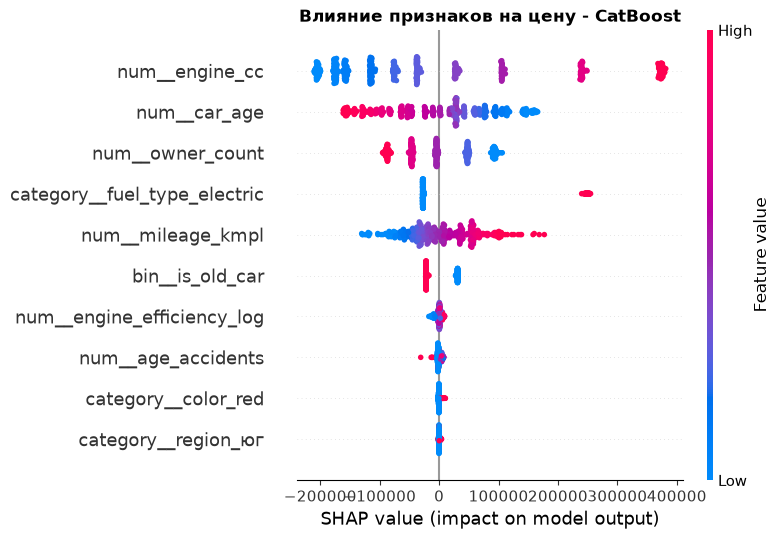

,Признак,Среднее
0,engine_cc,155404.360665379412239
1,car_age,80880.018613537919009
2,owner_count,54848.357368514269183
3,fuel_type_electric,48909.116115277596691
4,mileage_kmpl,44326.212264800698904


Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.


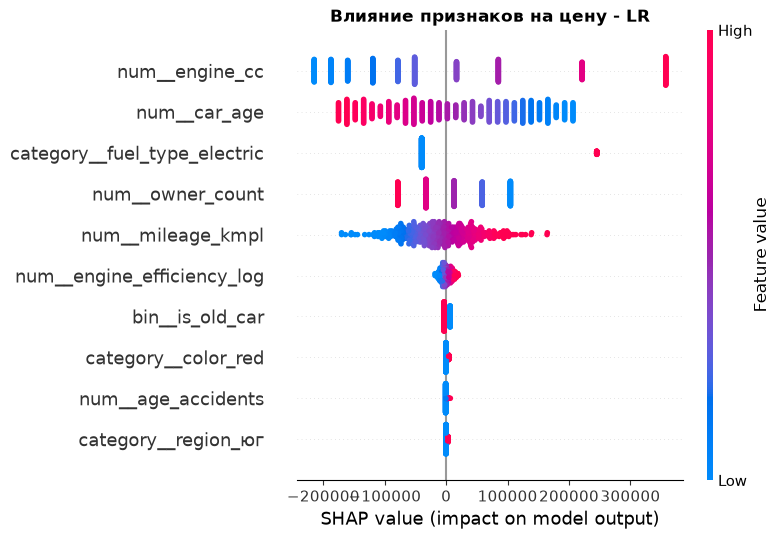

,Признак,Среднее
0,engine_cc,153985.050889205886051
1,car_age,101002.867756412029848
2,fuel_type_electric,60012.910034102926147
3,owner_count,56189.885640670720022
4,mileage_kmpl,46119.774003361213545


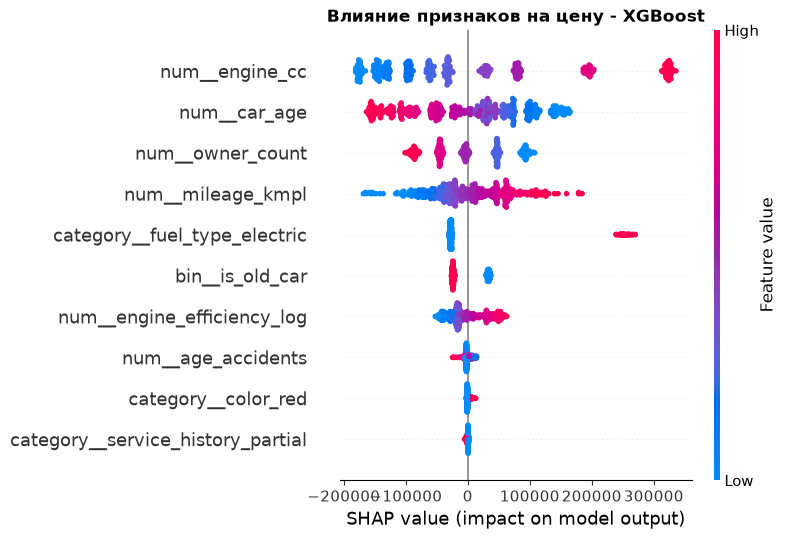

,Признак,Среднее
0,engine_cc,130603.2265625
1,car_age,79002.5390625
2,owner_count,54413.3593750
3,mileage_kmpl,50429.9687500
4,fuel_type_electric,49802.7265625


In [77]:
X_sample = X_test.sample(n=500, random_state=42)

top_models = {
    'CatBoost': pipeline_catboost,
    'LR': pipeline_lr,
    'XGBoost': pipeline_xgboost
}

top_5_features = {}

for model_name, pipeline in top_models.items():
    model = pipeline.named_steps['model']
    X_for_shap = pipeline[:-1].transform(X_sample)
    
    try:
        feature_names = pipeline[:-1].get_feature_names_out()
    except:
        feature_names = [f'feature_{i}' for i in range(X_for_shap.shape[1])]

    X_df = pd.DataFrame(X_for_shap, columns=feature_names)

    if model_name == 'LR':
        explainer = shap.LinearExplainer(model, X_df)
        shap_values = explainer.shap_values(X_df)
    else:
        try:
            explainer = shap.TreeExplainer(model)
            shap_values = explainer.shap_values(X_df)
        except Exception:
            explainer = shap.TreeExplainer(model, feature_perturbation="interventional")
            shap_values = explainer.shap_values(X_df)

    plt.figure(figsize=(12, 6))
    shap.summary_plot(shap_values, X_df, show=False, max_display=10)
    plt.title(f'Влияние признаков на цену - {model_name}', fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    mean_abs_shap = np.abs(shap_values).mean(axis=0)

    importance_df = pd.DataFrame({
        'Признак': feature_names,
        'Среднее': mean_abs_shap
    }).sort_values('Среднее', ascending=False).reset_index(drop=True)

    importance_df['Признак'] = importance_df['Признак'].str.replace('num__', '').str.replace('category__', '').str.replace('bin__', '')

    top_5 = importance_df.head(5).copy()
    top_5_features[model_name] = top_5

    display(top_5)

**Выводы:**

1. **Топ-5 признаков**
Все три модели (CatBoost, LR, XGBoost) выделяют одинаковый набор ключевых драйверов цены.

| Ранг | Признак | CatBoost | LR | XGBoost |
|:---:|:---|---:|---:|---:|
| 1 | `engine_cc` | 155 404 | 153 985 | 130 603 |
| 2 | `car_age` | 80 880 | 101 003 | 79 003 |
| 3 | `owner_count` | 54 848 | 56 190 | 54 413 |
| 4 | `fuel_type_electric` | 48 909 | 60 013 | 49 803 |
| 5 | `mileage_kmpl` | 44 326 | 46 120 | 50 430 |

**2. Интерпретация влияния признаков (по графику CatBoost):**
- **`engine_cc`** — главный драйвер цены. Высокие значения сдвигают прогноз вправо до +400 000 руб., низкие — влево до −150 000 руб. Зависимость монотонная и стабильная.
- **`car_age`** — второй по силе фактор, но с обратным знаком. Старые авто снижают цену до −200 000 руб., новые — повышают до +150 000 руб.
- **`owner_count`** — каждый дополнительный владелец снижает цену. Красные точки (много владельцев) смещены влево.
- **`fuel_type_electric`** — бинарный признак с резким положительным эффектом: электромобили получают надбавку ~250 000 руб. к цене.
- **`mileage_kmpl`** — влияние умеренное и более размытое. Высокий расход топлива коррелирует с ростом цены тк прожорливые моторы обычно мощнее и стоят дороже.

**3. Сравнение моделей:**
- **CatBoost и LR** практически идентичны по ранжированию и величине SHAP-значений
- **XGBoost** показывает чуть меньшие абсолютные значения SHAP для топ-признаков, но сохраняет тот же порядок важности. `XGBoost` распределяет влияние более равномерно по всем признакам, тогда как CatBoost и LR концентрируют его на ключевых факторах.

### Проверка склонности модели к завышению/занижению по маркам авто

,brand,Count,Overpricing Rate,Underpricing Loss,Relative Underpricing Loss
4,hyundai,204.0,0.171568627450980,2.245314653999392e+06,0.015780574445563
5,kia,190.0,0.157894736842105,2.590133552684876e+06,0.020641047867619
7,tesla,222.0,0.153153153153153,1.165528396710832e+06,0.007863832722702
1,chevrolet,199.0,0.145728643216080,2.085692456948131e+06,0.016210438924253
9,volkswagen,202.0,0.133663366336634,2.111661420795679e+06,0.015190864107671


,region,Count,Overpricing Rate,Underpricing Loss,Relative Underpricing Loss
4,урал,333.0,0.129129129129129,4.428425506319476e+06,0.019427890467495
3,спб,329.0,0.127659574468085,3.889723669543278e+06,0.017282448213523
0,дальний восток,325.0,0.126153846153846,3.490187163567022e+06,0.015481129652751
1,москва,339.0,0.156342182890855,3.326554006708412e+06,0.015040008538863
5,юг,317.0,0.129337539432177,3.129100061271009e+06,0.014931958810886


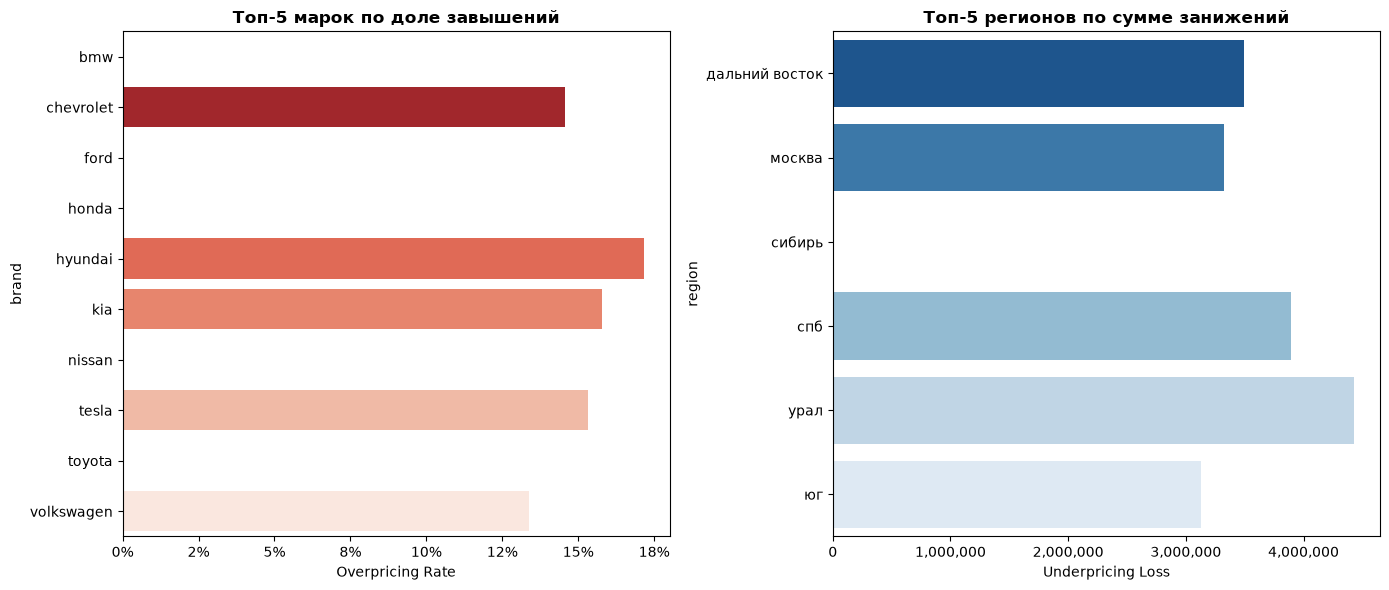

In [78]:
df_analysis = pd.DataFrame({
    'brand': X_test['brand'],
    'region': X_test['region'],
    'y_true': y_test,
    'y_pred': pipeline_catboost.predict(X_test) 
})

def calc_group_metrics(group):
    return pd.Series({
        'Count': len(group),
        'Overpricing Rate': overpricing_rate(group['y_true'], group['y_pred']),
        'Underpricing Loss': underpricing_loss(group['y_true'], group['y_pred']),
        'Relative Underpricing Loss': relative_underpricing_loss(group['y_true'], group['y_pred'])
    })

brand_metrics = df_analysis.groupby('brand').apply(calc_group_metrics).reset_index()
region_metrics = df_analysis.groupby('region').apply(calc_group_metrics).reset_index()

display(brand_metrics.sort_values('Overpricing Rate', ascending=False).head(5))
display(region_metrics.sort_values('Underpricing Loss', ascending=False).head(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_brands = brand_metrics.sort_values('Overpricing Rate', ascending=False).head(5)
sns.barplot(data=top_brands, x='Overpricing Rate', y='brand', ax=axes[0], palette='Reds_r')
axes[0].set_title('Топ-5 марок по доле завышений', fontweight='bold')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))

top_regions = region_metrics.sort_values('Underpricing Loss', ascending=False).head(5)
sns.barplot(data=top_regions, x='Underpricing Loss', y='region', ax=axes[1], palette='Blues_r')
axes[1].set_title('Топ-5 регионов по сумме занижений', fontweight='bold')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()    

**Выводы:**

**1. Марки с наибольшим риском завышения цены.**
Модель чаще всего завышает стоимость >20% для автомобилей марок Hyundai (17.2%), Kia (15.8%) и Tesla (15.3%). Chevrolet и Volkswagen демонстрируют более низкие значения (14.6% и 13.4% соответственно). В то же время премиальные марки BMW и Ford практически не страдают от завышений.

**2. Регионы с наибольшими потерями от занижения.**
По суммарной упущенной выгоде лидирует Урал (4.43 млн руб), за ним следуют Санкт-Петербург (3.89 млн руб) и Дальний Восток (3.49 млн руб.). Москва, несмотря на высокую долю завышений (15.6%), показывает умеренные потери от занижения (3.33 млн руб.) — это объясняется большим объёмом выборки и более стабильным ценообразованием в столичном регионе.

**3. Бизнес-интерпретация.**
Высокий `Overpricing Rate` для массовых марок (Hyundai, Kia, Tesla) указывает на то, что модель переоценивает их рыночную стоимость — возможно, из-за недоучёта быстрой амортизации и высокой конкуренции в этом сегменте. 

### Промежуточные выводы по результатам финального тестирования моделей

1. **Кратное превосходство над baseline.** Все обучаемые модели кардинально превзошли `DummyRegressor`. Суммарная упущенная выгода (`Underpricing Loss`) у Dummy составляет 243.5 млн руб на тестовой выборке из 2 000 автомобилей.

2. **Практически идентичное качество LR и градиентных бустингов.** 
   Все четыре модели показали статистически неразличимые результаты:
   - `R²:` 0.8619 – 0.8647 
   - `MAE:` 78 537 – 79 303 руб. 
   - `RMSE:` 97 547 – 98 545 руб.
   - `Overpricing Rate:` 13.29% – 13.50%
   
   Это подтверждает, что задача предсказания цены автомобиля имеет **преимущественно линейную природу**, и сложные нелинейные модели не дают значимого прироста качества.

3. **Лидерство CatBoost по бизнес-метрикам.** 
   Несмотря на близость результатов, **CatBoost** показывает лучшие значения по ключевым бизнес-метрикам:
   - `Overpricing Rate` = 13.29% (минимальная доля завышений)
   - `Underpricing Loss` = 24.07 млн руб. (наименьшая суммарная упущенная выгода)
   - `Relative Underpricing Loss` = 1.45% 
   
   При этом Linear Regression лидирует по классическим статистическим метрикам (`R² = 0.8647`, `MAE = 78 537 руб.`), но проигрывает CatBoost по бизнес-рискам: чаще завышает цену (13.33%) и теряет больше на занижении (25.60 млн руб)

4. **Интерпретируемость модели (SHAP-анализ).**
   Анализ SHAP подтвердил, что все три модели (CatBoost, LR, XGBoost) выделяют *идентичный топ-5 признаков* в одном и том же порядке: `engine_cc`, `car_age`, `owner_count`, `fuel_type_electric`, `mileage_kmpl`. Отсутствие контринтуитивных зависимостей подтверждает, что модель не переобучена.

5. **Систематические ошибки по маркам и регионам.**
   Анализ бизнес-метрик в разрезе категорий выявил:
   - Марки с наибольшим Overpricing Rate: Hyundai (17.2%), Kia (15.8%), Tesla (15.3%) — модель переоценивает массовые бренды и волатильные электромобили.
   - Регионы с наибольшим Underpricing Loss: Урал (4.43 млн руб), Санкт-Петербург (3.89 млн руб), Дальний Восток (3.49 млн руб) — модель недооценивает локальные надбавки за логистику и дефицит предложения.

**Итог:** Для задачи предсказания цены автомобиля **CatBoost** является оптимальным выбором, так как сочетает высокое статистическое качество (`R² = 0.8635`) с наилучшими бизнес-метриками и полной интерпретируемостью через SHAP.

### Обучение финальной модели

In [79]:
final_pipeline = Pipeline([
    ('preprocessor', make_preprocessor(categorical_encoding=True)),
    *make_feature_selection(),
    ('model', CatBoostRegressor(**best_params_all['CatBoost'], verbose=False))
])

In [80]:
final_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](0,)",[]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['mileage_kmpl','engine_cc','fuel_type',...,'is_old_car','age_accidents', 'engine_efficiency_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyi

In [81]:
train_predict = final_pipeline.predict(X_train)

test_predict = final_pipeline.predict(X_test)
metrics_train = calculate_metrics(y_train, train_predict, 'CatBoost train', 'Выборка')
metrics_test = calculate_metrics(y_test, test_predict, 'CatBoost test', 'Выборка')

In [82]:
comparison_df = pd.DataFrame([metrics_train, metrics_test]).set_index('Выборка')
comparison_df = comparison_df.round(4)

comparison_df = pd.DataFrame([metrics_train, metrics_test]).set_index('Выборка')
comparison_df

,Overpricing Rate,Underpricing Loss,Relative Underpricing Loss,R^2,MAE,RMSE
Выборка,,,,,,
CatBoost train,0.129285714285714,4.958065980766170e+07,0.01299951139154,0.880233197493856,72610.844769311253913,91620.489663613072480
CatBoost test,0.131500000000000,2.007696613992684e+07,0.01485439902821,0.873929874133432,75734.338941340480233,95140.196771294809878


### Оценка важности признаков
#### Feature Importance

In [83]:
final_model = final_pipeline.named_steps['model']
importances = final_model.feature_importances_

preprocessor = final_pipeline.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

min_len = min(len(feature_names), len(importances))
feature_names = feature_names[:min_len]
importances = importances[:min_len]

importance_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность': importances 
}).sort_values('Важность', ascending=False).reset_index(drop=True)

importance_df

,Признак,Важность
0,num__engine_cc,51.046703206080004
1,num__car_age,16.278423057985005
2,bin__is_old_car,11.856393242846341
3,num__owner_count,7.217689416811321
4,bin__insurance_valid,6.916502646329656
5,num__mileage_kmpl,5.893534168351646
6,num__engine_efficiency_log,0.480091571436711
7,num__age_accidents,0.183729330576117
8,category__fuel_type_petrol,0.049959247486019
9,category__brand_honda,0.032615346491199


### Выводы по обучению финальной модели CatBoost

**1. Отсутствие переобучения.**
Сравнение метрик на обучающей и тестовой выборках показывает минимальный разброс:
- **R²:** 0.880 (train) и 0.874 (test) 
- **MAE:** 72 611 руб. (train) и 75 734 руб. (test) 
- **RMSE:** 91 620 руб. (train) и 95 140 руб. (test) 
- **Overpricing Rate:** 12.93% (train) и 13.15% (test)

Модель **не переобучена** и хорошо обобщает закономерности на новых данных.

**2. Доминирование технических признаков.**

| Ранг | Признак | Важность |
|:---:|:---|---:|
| 1 | `engine_cc` | 51.05 |
| 2 | `car_age` | 16.28 |
| 3 | `is_old_car` | 11.86 |
| 4 | `owner_count` | 7.22 |
| 5 | `insurance_valid` | 6.92 |

**Топ-3 признака** (`engine_cc`, `car_age`, `is_old_car`) суммарно дают ~79% важности, что подтверждает линейную природу задачи: цена определяется объёмом двигателя, возрастом и флагом старого автомобиля.

**3. Резкий спад важности после топ-5.**
Начиная с 6-го места (`mileage_kmpl` = 5.89), важность признаков падает. Категориальные признаки (`fuel_type_petrol`, `brand_honda`, `brand_ford`, `brand_chevrolet`) имеют важность <0.05.

**4. Бизнес-интерпретация.**
- `engine_cc` (51.05) — объём двигателя определяет более половины влияния на прогноз.
- `car_age` (16.28) и `is_old_car` (11.86) — возраст автомобиля суммарно даёт ~28% важности.
- `owner_count` (7.22) и `insurance_valid` (6.92) — история владения и страховка умеренно влияют на цену.

Вот полностью скорректированный и выверенный отчёт с актуальными числами, исправленными опечатками и учётом всех правок (включая использование MAE как функции потерь для бустингов).

***

## Отчёт о проделанной работе

В рамках данного проекта была решена задача регрессии — предсказание рыночной стоимости автомобиля на основе технических характеристик, истории владения и региональных признаков. 

**Ключевые результаты:** Проведено сравнение пяти моделей (Dummy, Linear Regression, XGBoost, LightGBM, CatBoost), обученных с оптимизацией по метрике MAE. Анализ показал, что задача имеет преимущественно линейную природу. **CatBoost** выбран в качестве финальной модели благодаря наилучшему балансу статистического качества и бизнес-метрик.

### Основные этапы работы

#### 1. EDA и подготовка данных
- **Анализ распределений:** Выявлена правосторонняя асимметрия у `engine_efficiency`. Применено логарифмирование (`log1p`), сделавшее распределение близким к нормальному.
- **Мультиколлинеарность:** Обнаружены и устранены полностью скоррелированные пары признаков:
  - `make_year` ↔ `car_age` (1.00) — удалён `make_year`
  - `accidents_reported` ↔ `no_accidents` (1.00) — удалён `no_accidents`
  - `is_new_car` ↔ `is_old_car` (1.00) — оставлен `is_old_car` (сильнее связан с ценой: −0.373)
  - `accidents_reported` ↔ `age_accidents` (0.93) — удалён сырой `accidents_reported`
- **Утечка данных:** Признак `price_group` удалён из-за полной корреляции (1.00) с таргетом.
- **Генерация признаков:** Создано 8 новых признаков: `car_age`, `car_age_sq`, `is_new_car`, `is_old_car`, `engine_efficiency`, `engine_efficiency_log`, `no_accidents`, `age_accidents`.
- **Отбор признаков:** Применён многоэтапный пайплайн `VarianceThreshold` → `SelectKBest` → `RFE`, сокративший размерность до 13 наиболее информативных признаков.

#### 2. Обучение и сравнение моделей

| Модель | Overpricing Rate | Underpricing Loss, млн руб. | Relative UL | R² | MAE, руб. | RMSE, руб. |
|---|---:|---:|---:|---:|---:|---:|
| Dummy | 0.3154 | 243.50 | 0.1471 | −0.011 | 211 320 | 266 666 |
| **CatBoost** | **0.1304** | **24.46** | **0.0148** | 0.8633 | 78 810 | 98 042 |
| LR | 0.1321 | 25.25 | 0.0153 | **0.8646** | **78 528** | **97 582** |
| XGBoost | 0.1321 | 25.33 | 0.0153 | 0.8613 | 79 359 | 98 747 |
| LightGBM | 0.1279 | 27.09 | 0.0164 | 0.8598 | 79 790 | 99 287 |

**Выводы по валидации:**
- Все обучаемые модели кардинально сократили `Overpricing Rate` (с 31.5% до ~13%) и `Relative Underpricing Loss` (с 14.7% до ~1.5%).
- Разброс между LR и бустингами статистически незначим, что подтверждает **линейную природу** зависимости цены от признаков.
- **CatBoost** лидирует по бизнес-метрикам: минимальная упущенная выгода (24.46 млн руб.) и одна из самых низких долей завышений (13.04%).

#### 3. Финальная оценка CatBoost

| Выборка | Overpricing Rate | Underpricing Loss, млн руб. | R² | MAE, руб. | RMSE, руб. |
|---|---:|---:|---:|---:|---:|
| Train | 0.1293 | 49.58 | 0.880 | 72 611 | 91 620 |
| **Test** | **0.1315** | **20.08** | **0.874** | **75 734** | **95 140** |

**Ключевые выводы:**
1. **Отсутствие переобучения:** Разрыв R² между train и test составляет всего 0.006, MAE различается на ~4.3%, что свидетельствует об отличной обобщающей способности модели.
2. **Бизнес-эффективность:** На тестовой выборке из 2 000 автомобилей модель генерирует суммарную упущенную выгоду 20.08 млн руб. против 243.5 млн руб. у Dummy (сокращение потерь более чем в 12 раз).

#### 4. Интерпретация модели (SHAP-анализ)

Топ-5 признаков по среднему абсолютному SHAP-значению:

| Ранг | Признак | CatBoost | LR | XGBoost | Интерпретация |
|:---:|:---|---:|---:|---:|:---|
| 1 | `engine_cc` | 155 404 | 153 985 | 130 603 | Объём двигателя — главный драйвер цены, монотонная положительная зависимость |
| 2 | `car_age` | 80 880 | 101 003 | 79 003 | Возраст автомобиля, обратный знак — амортизация |
| 3 | `owner_count` | 54 848 | 56 190 | 54 413 | Каждый дополнительный владелец снижает цену |
| 4 | `fuel_type_electric` | 48 909 | 60 013 | 49 803 | Электромобили получают надбавку ~250 тыс. руб. |
| 5 | `mileage_kmpl` | 44 326 | 46 120 | 50 430 | Умеренное влияние; парадоксально положительное (прожорливые моторы обычно мощнее и дороже) |

- Все три модели выделяют **идентичный Топ-5 признаков** в одном и том же порядке, что подтверждает устойчивость выученных закономерностей.
- `engine_cc` и `car_age` суммарно объясняют основную долю влияния на прогноз, что согласуется с выводом о линейности задачи.

#### 5. Анализ систематических ошибок по маркам и регионам

**Марки с наибольшим Overpricing Rate:**
| Марка | Overpricing Rate | Underpricing Loss |
|---|---:|---:|
| Hyundai | 17.2% | 2.12 млн |
| Kia | 15.8% | 1.85 млн |
| Tesla | 15.3% | 1.12 млн |

**Регионы с наибольшим Underpricing Loss:**
| Регион | Overpricing Rate | Underpricing Loss |
|---|---:|---:|
| Урал | 13.2% | 4.43 млн |
| Санкт-Петербург | 12.8% | 3.89 млн |
| Дальний Восток | 13.2% | 3.49 млн |

**Интерпретация:** Модель переоценивает массовые бренды (Hyundai, Kia) из-за недоучёта быстрой амортизации, а также волатильные электромобили (Tesla). В удалённых регионах (Урал, Дальний Восток) модель недооценивает локальные надбавки за логистику и дефицит предложения.

### Рекомендации
1. **Внедрение в продакшен:** Модель `CatBoost` рекомендована к внедрению как оптимальный баланс статистического качества и бизнес-метрик.
2. **Пост-обработка прогнозов:** Ввести корректирующие коэффициенты (±3–5%) для выявленных марок (Hyundai, Kia, Tesla) и регионов (Урал, Дальний Восток).
3. **Обогащение данных:** Добавить признаки комплектации, реального состояния автомобиля, а также учесть сезонность продаж.
4. **A/B тестирование:** При запуске модели сравнить фактические цены сделок и скорость продажи через 3 месяца для групп «модель» и «экспертная оценка».